# Lending Game — Part 1: Exploratory Data Analysis

**We are lender 3**, so `signal3` is our private signal; `signal1` and `signal2` belong to the
other two lenders and appear only in the historical file.

This notebook describes the data and works out what it implies for encoding and transforming the
variables. It fits no model beyond univariate AUC used as a descriptive statistic.

**Outputs:** figures in `report/figures/`, written up in `report/eda_report.md` (short) and
`report/eda_report_detailed.md` (long).

---

## 0. Setup

In [1]:
import sys
from pathlib import Path

sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

from src.config import PAST_LOANS, NEW_APPS_R1, FIGURES_DIR, SEED, INCOME_TOPCODE

# Reproducibility: every random operation in this notebook uses this seed.
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "figure.autolayout": False})

SIGNALS = ["signal1", "signal2", "signal3"]
OUR_SIGNAL = "signal3"
PUBLIC = ["sex", "employment", "married", "income"]

print(f"seed = {SEED}  |  figures -> {FIGURES_DIR.relative_to(FIGURES_DIR.parents[1])}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

seed = 42  |  figures -> report/figures
pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


### Helper functions

- **`wilson_ci`** — 95% Wilson score interval for a default rate, used for every grouped and
  binned rate below. It is preferred to the normal approximation because several bins have small
  `n` or rates close to 0.
- **`rate_by`** — group size, defaults, default rate and its CI, for any grouping.
- **`signal_bins`** — **bins the signal zeros as their own group, and computes the quantile bins
  on the strictly positive values only.** About 21% of each signal is exactly 0, so the zeros
  would otherwise dominate the lowest bins; section 4 shows they also behave quite differently
  from small positive values.

In [2]:
def wilson_ci(k, n, conf=0.95):
    """Wilson score interval for a binomial proportion.

    Preferred over the normal approximation because several bins here have small n and/or
    default rates close to 0, where the Wald interval can fall outside [0, 1].

    Parameters
    ----------
    k, n : int or array-like
        Number of successes (defaults) and number of trials (group size).
    conf : float
        Confidence level, default 0.95.

    Returns
    -------
    (lo, hi) : np.ndarray
        Lower and upper bounds, as proportions.
    """
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    z = stats.norm.ppf(0.5 + conf / 2)
    with np.errstate(invalid="ignore", divide="ignore"):
        p = k / n
        denom = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / denom
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def rate_by(df, key, target="default", conf=0.95, observed=True):
    """Default rate by group, with group size and a Wilson CI.

    `key` is anything groupby accepts: a column name, a list of them, or a Series of bin labels.
    """
    g = df.groupby(key, observed=observed)[target].agg(n="size", defaults="sum")
    g["rate"] = g["defaults"] / g["n"]
    lo, hi = wilson_ci(g["defaults"].to_numpy(), g["n"].to_numpy(), conf)
    g["ci_lo"], g["ci_hi"] = lo, hi
    g["ci_pm_pp"] = (hi - lo) / 2 * 100  # half-width in percentage points
    return g


def signal_bins(s, q=10, zero_label="exactly 0"):
    """Bin a signal: zeros in their own bin, q quantile bins over the strictly positive values.

    Returns an ordered Categorical so that groupby/plots keep zero first, then q1..qQ.
    """
    labels = [f"q{i}" for i in range(1, q + 1)]
    pos = pd.qcut(s.where(s > 0), q, labels=labels)
    out = pos.astype(object).where(s > 0, zero_label)
    return pd.Categorical(out, categories=[zero_label] + labels, ordered=True)


def pct(x, nd=2):
    """Format a proportion as a percentage string."""
    return f"{x * 100:.{nd}f}%"


def savefig(fig, name):
    """Save a figure into report/figures/ and report the path."""
    path = FIGURES_DIR / name
    fig.savefig(path)
    print(f"saved {path.name}")
    return path

---

## 1. Loading and basic inspection

The two raw files are read-only inputs from the course and are never modified.

In [3]:
past = pd.read_csv(PAST_LOANS)
new = pd.read_csv(NEW_APPS_R1)

print(f"PastLoans        : {past.shape[0]:,} rows x {past.shape[1]} cols")
print(f"NewApplications  : {new.shape[0]:,} rows x {new.shape[1]} cols")
print()
print("--- dtypes ---")
print(pd.DataFrame({"PastLoans": past.dtypes.astype(str),
                    "NewApplications": new.dtypes.astype(str)}).fillna("— absent —").to_string())

PastLoans        : 100,000 rows x 8 cols
NewApplications  : 100,000 rows x 6 cols

--- dtypes ---
             PastLoans NewApplications
default          int64      — absent —
employment         str             str
id          — absent —           int64
income           int64           int64
married          int64           int64
sex                str             str
signal1        float64      — absent —
signal2        float64      — absent —
signal3        float64         float64


In [4]:
print("--- missing values per column ---")
print(pd.DataFrame({"PastLoans": past.isna().sum(),
                    "NewApplications": new.isna().sum()}).fillna("—").to_string())
print()
print(f"total missing, PastLoans       : {int(past.isna().sum().sum())}")
print(f"total missing, NewApplications : {int(new.isna().sum().sum())}")
print()
print("--- id column ---")
print(f"PastLoans has an 'id' column      : {'id' in past.columns}")
print(f"NewApplications has an 'id' column: {'id' in new.columns}")
if "id" in new.columns:
    contiguous = bool((new["id"].sort_values().to_numpy() == np.arange(1, len(new) + 1)).all())
    print(f"  id range {new['id'].min()}..{new['id'].max()}, "
          f"{new['id'].nunique():,} unique, exactly 1..N contiguous: {contiguous}")
print()
print("NOTE: PastLoans has no identifier, so past loans cannot be linked to new applicants.")

--- missing values per column ---
           PastLoans NewApplications
default          0.0               —
employment       0.0             0.0
id                 —             0.0
income           0.0             0.0
married          0.0             0.0
sex              0.0             0.0
signal1          0.0               —
signal2          0.0               —
signal3          0.0             0.0

total missing, PastLoans       : 0
total missing, NewApplications : 0

--- id column ---
PastLoans has an 'id' column      : False
NewApplications has an 'id' column: True
  id range 1..100000, 100,000 unique, exactly 1..N contiguous: True

NOTE: PastLoans has no identifier, so past loans cannot be linked to new applicants.


### Duplicates

`PastLoans` contains 68 exactly-duplicated rows. Before treating them as a data-quality problem,
it is worth asking *where* they sit — because the signals are continuous to 8 significant digits,
two genuinely independent borrowers should essentially never collide unless their signals are all
exactly 0.

In [5]:
n_dup_past = int(past.duplicated().sum())
n_dup_new = int(new.duplicated().sum())
print(f"exactly duplicated rows -- PastLoans: {n_dup_past}  |  NewApplications: {n_dup_new}")
print()

all_signals_zero = (past[SIGNALS] == 0).all(axis=1)
print(f"rows with all three signals exactly 0          : {int(all_signals_zero.sum()):,}")
print(f"  ... of which duplicated (keep=False)         : {int(past[all_signals_zero].duplicated(keep=False).sum())}")
print(f"rows with at least one positive signal         : {int((~all_signals_zero).sum()):,}")
print(f"  ... of which duplicated (keep=False)         : {int(past[~all_signals_zero].duplicated(keep=False).sum())}")
print()
dups = past[past.duplicated(keep=False)]
print(f"employment mix of the duplicated rows: {dups['employment'].value_counts().to_dict()}")
print(f"of the {len(dups)} rows involved, {int((dups['income'] == 0).sum())} have income == 0; the other "
      f"{int((dups['income'] > 0).sum())} are retired applicants who also share an income value")
print()
print("the 6 duplicated rows that do NOT have income == 0:")
print(dups[dups["income"] > 0].sort_values(["income", "sex"]).to_string())
print()

PUB = ["sex", "employment", "married", "income"]
zero_rows = past[all_signals_zero]
n_zero = len(zero_rows)
n_profiles = zero_rows[PUB].drop_duplicates().shape[0]
n_fullrows = zero_rows.drop_duplicates().shape[0]
split_by_outcome = sum(1 for _, s in zero_rows.groupby(PUB, observed=True)
                       if len(s) > 1 and s["default"].nunique() > 1)
groups = past.groupby(list(past.columns), observed=True).size()
groups = groups[groups > 1]

print("--- reconciling the different counts, which measure different things ---")
print(f"  all-signals-zero rows                                      : {n_zero:,}")
print(f"  distinct PUBLIC profiles (sex, employment, married, income): {n_profiles:,}")
print(f"    -> rows beyond one per public profile                    : {n_zero - n_profiles}")
print(f"  distinct FULL rows (all 8 columns, i.e. including default) : {n_fullrows:,}")
print(f"    -> rows beyond one per full row = past.duplicated().sum(): {n_zero - n_fullrows}")
print(f"  public-profile groups whose rows differ in 'default'       : {split_by_outcome}")
print(f"    -> {n_zero - n_profiles} - {split_by_outcome} = {n_zero - n_profiles - split_by_outcome}, "
      f"which is exactly the duplicate count")
print()
print(f"  the two ways of counting duplicated rows:")
print(f"    past.duplicated().sum()          = {int(past.duplicated().sum())}  (repeats only, keep='first')")
print(f"    past.duplicated(keep=False).sum()= {int(past.duplicated(keep=False).sum())}  (every row in a duplicate group)")
print(f"    across {len(groups)} duplicate groups of sizes {sorted(groups.to_list())}")
print(f"    and indeed {int(groups.sum())} - {len(groups)} = {int((groups - 1).sum())}")
print()
print("EVIDENCE: every duplicate sits inside the all-signals-zero subset, and there are zero")
print("duplicates among the 98,742 rows with at least one positive signal. Once all three signals")
print(f"are 0, a row is pinned down by (sex, employment, married, income) -- and those {n_zero:,}")
print(f"rows occupy only {n_profiles:,} distinct public profiles, so collisions are unavoidable.")
print("A collision becomes a true duplicate only when the two borrowers ALSO share an outcome,")
print(f"which is why {n_zero - n_profiles} excess rows yield {int(past.duplicated().sum())} duplicates "
      f"rather than {n_zero - n_profiles}.")
print()
print("INTERPRETATION (ours, not given in the brief): these look like distinct borrowers who")
print("happen to share identical recorded values, not repeated records. We therefore do NOT")
print("recommend de-duplicating. Open question for the team / lecturer.")

exactly duplicated rows -- PastLoans: 68  |  NewApplications: 0

rows with all three signals exactly 0          : 1,258
  ... of which duplicated (keep=False)         : 79
rows with at least one positive signal         : 98,742
  ... of which duplicated (keep=False)         : 0

employment mix of the duplicated rows: {'unemployed': 71, 'retired': 6, 'student': 2}
of the 79 rows involved, 73 have income == 0; the other 6 are retired applicants who also share an income value

the 6 duplicated rows that do NOT have income == 0:
      sex employment  married  income  signal1  signal2  signal3  default
54637   F    retired        0    4525      0.0      0.0      0.0        0
56385   F    retired        0    4525      0.0      0.0      0.0        0
2567    M    retired        1    4711      0.0      0.0      0.0        0
29980   M    retired        1    4711      0.0      0.0      0.0        0
23010   F    retired        0    6659      0.0      0.0      0.0        0
26670   F    retired     

--- reconciling the different counts, which measure different things ---
  all-signals-zero rows                                      : 1,258
  distinct PUBLIC profiles (sex, employment, married, income): 1,185
    -> rows beyond one per public profile                    : 73
  distinct FULL rows (all 8 columns, i.e. including default) : 1,190
    -> rows beyond one per full row = past.duplicated().sum(): 68
  public-profile groups whose rows differ in 'default'       : 5
    -> 73 - 5 = 68, which is exactly the duplicate count

  the two ways of counting duplicated rows:


    past.duplicated().sum()          = 68  (repeats only, keep='first')
    past.duplicated(keep=False).sum()= 79  (every row in a duplicate group)
    across 11 duplicate groups of sizes [2, 2, 2, 2, 3, 6, 8, 10, 10, 13, 21]
    and indeed 79 - 11 = 68

EVIDENCE: every duplicate sits inside the all-signals-zero subset, and there are zero
duplicates among the 98,742 rows with at least one positive signal. Once all three signals
are 0, a row is pinned down by (sex, employment, married, income) -- and those 1,258
rows occupy only 1,185 distinct public profiles, so collisions are unavoidable.
A collision becomes a true duplicate only when the two borrowers ALSO share an outcome,
which is why 73 excess rows yield 68 duplicates rather than 73.

INTERPRETATION (ours, not given in the brief): these look like distinct borrowers who
happen to share identical recorded values, not repeated records. We therefore do NOT
recommend de-duplicating. Open question for the team / lecturer.


### Categorical variables: are they coded the same way in both files?

This matters because any encoding we fit on `PastLoans` has to apply unchanged to the new
applicants. `repr()` is used so that stray whitespace or case differences would show up.

In [6]:
for col in ["sex", "employment", "married"]:
    a = past[col].value_counts().sort_index()
    b = new[col].value_counts().sort_index()
    cmp = pd.DataFrame({"past_n": a, "past_%": (a / len(past) * 100).round(2),
                        "new_n": b, "new_%": (b / len(new) * 100).round(2)})
    cmp["diff_pp"] = (cmp["new_%"] - cmp["past_%"]).round(2)
    print(f"--- {col} ---")
    print(cmp.to_string())
    print(f"  levels in PastLoans      : {[repr(v) for v in sorted(past[col].unique(), key=str)]}")
    print(f"  levels in NewApplications: {[repr(v) for v in sorted(new[col].unique(), key=str)]}")
    print(f"  identical level sets     : {set(past[col].unique()) == set(new[col].unique())}")
    print()
print("All level sets match exactly: same spelling, same case, no whitespace variants,")
print("no level present in one file and absent from the other.")
print(f"employment has exactly {past['employment'].nunique()} categories "
      f"({', '.join(sorted(past['employment'].unique()))}), confirming the course brief.")

--- sex ---
     past_n  past_%  new_n  new_%  diff_pp
sex                                       
F     42669   42.67  42832  42.83     0.16
M     57331   57.33  57168  57.17    -0.16


  levels in PastLoans      : ["'F'", "'M'"]
  levels in NewApplications: ["'F'", "'M'"]
  identical level sets     : True

--- employment ---
            past_n  past_%  new_n  new_%  diff_pp
employment                                       
employed     57936   57.94  57825  57.82    -0.12
retired      11582   11.58  11588  11.59     0.01
student      16183   16.18  16050  16.05    -0.13
unemployed   14299   14.30  14537  14.54     0.24
  levels in PastLoans      : ["'employed'", "'retired'", "'student'", "'unemployed'"]
  levels in NewApplications: ["'employed'", "'retired'", "'student'", "'unemployed'"]
  identical level sets     : True

--- married ---
         past_n  past_%  new_n  new_%  diff_pp
married                                       
0         39178   39.18  38904   38.9    -0.28
1         60822   60.82  61096   61.1     0.28
  levels in PastLoans      : ['np.int64(0)', 'np.int64(1)']
  levels in NewApplications: ['np.int64(0)', 'np.int64(1)']
  identical level sets     

In [7]:
print("--- value ranges ---")
rows = []
for nm, df in [("PastLoans", past), ("NewApplications", new)]:
    for col in ["married", "income", "signal1", "signal2", "signal3", "default"]:
        if col not in df.columns:
            continue
        s = df[col]
        rows.append({"file": nm, "column": col, "min": s.min(), "max": s.max(),
                     "mean": round(float(s.mean()), 4), "median": s.median(),
                     "n_distinct": s.nunique()})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("--- sanity checks ---")
print(f"negative incomes                 : past {int((past['income'] < 0).sum())}, new {int((new['income'] < 0).sum())}")
print(f"incomes above the €1M top-code   : past {int((past['income'] > INCOME_TOPCODE).sum())}, new {int((new['income'] > INCOME_TOPCODE).sum())}")
for c in SIGNALS:
    print(f"{c} outside [0, 1]            : {int(((past[c] < 0) | (past[c] > 1)).sum())}")
print(f"signal3 outside [0, 1] (new)     : {int(((new['signal3'] < 0) | (new['signal3'] > 1)).sum())}")
print(f"married values outside {{0, 1}}    : past {int((~past['married'].isin([0, 1])).sum())}, new {int((~new['married'].isin([0, 1])).sum())}")
print(f"default values outside {{0, 1}}    : {int((~past['default'].isin([0, 1])).sum())}")

--- value ranges ---
           file  column  min            max       mean      median  n_distinct
      PastLoans married  0.0       1.000000     0.6082    1.000000           2
      PastLoans  income  0.0 1000000.000000 18646.2539 9370.000000       33378
      PastLoans signal1  0.0       0.999975     0.4177    0.448209       78999
      PastLoans signal2  0.0       0.999986     0.4157    0.444645       78956
      PastLoans signal3  0.0       0.999965     0.4149    0.440936       78785
      PastLoans default  0.0       1.000000     0.0995    0.000000           2
NewApplications married  0.0       1.000000     0.6110    1.000000           2
NewApplications  income  0.0 1000000.000000 18724.4533 9349.000000       33369
NewApplications signal3  0.0       0.999994     0.4162    0.446395       78908

--- sanity checks ---
negative incomes                 : past 0, new 0
incomes above the €1M top-code   : past 0, new 0
signal1 outside [0, 1]            : 0
signal2 outside [0, 1]        

In [8]:
print("--- income top-coding at €1,000,000 ---")
for nm, df in [("PastLoans", past), ("NewApplications", new)]:
    tc = df["income"] == INCOME_TOPCODE
    nxt = sorted(df.loc[~tc, "income"].unique())[-1]
    print(f"{nm:16s}: {int(tc.sum()):>3} rows top-coded ({pct(tc.mean(), 3)}); "
          f"next highest observed income = €{nxt:,}")
print()
print("The gap between the top-code and the next highest value is small, so €1M is a genuine")
print("pile-up at the cap rather than a round-number coincidence.")
print()
print("--- income == 0 ---")
for nm, df in [("PastLoans", past), ("NewApplications", new)]:
    z = df["income"] == 0
    print(f"{nm:16s}: {int(z.sum()):>6,} rows with income exactly 0 ({pct(z.mean())})")

--- income top-coding at €1,000,000 ---
PastLoans       :  71 rows top-coded (0.071%); next highest observed income = €996,721
NewApplications :  82 rows top-coded (0.082%); next highest observed income = €999,902

The gap between the top-code and the next highest value is small, so €1M is a genuine
pile-up at the cap rather than a round-number coincidence.

--- income == 0 ---
PastLoans       : 17,035 rows with income exactly 0 (17.04%)
NewApplications : 17,159 rows with income exactly 0 (17.16%)


---

## 2. The target: `default`

In [9]:
vc = past["default"].value_counts().sort_index()
overall_rate = past["default"].mean()
lo, hi = wilson_ci(int(past["default"].sum()), len(past))

print(f"repaid   (default=0): {vc[0]:>6,}  ({pct(vc[0] / len(past))})")
print(f"defaulted(default=1): {vc[1]:>6,}  ({pct(vc[1] / len(past))})")
print()
print(f"overall default rate : {pct(overall_rate, 3)}   95% CI [{pct(lo, 3)}, {pct(hi, 3)}]")
print(f"class ratio          : 1 default per {vc[0] / vc[1]:.2f} repaid  (~1:9)")
print()
print("Imbalance is moderate, not severe: ~9,947 defaults is ample for estimating group rates,")
print("and every subgroup examined below has enough defaults for a usably narrow interval.")

repaid   (default=0): 90,053  (90.05%)
defaulted(default=1):  9,947  (9.95%)

overall default rate : 9.947%   95% CI [9.763%, 10.134%]
class ratio          : 1 default per 9.05 repaid  (~1:9)

Imbalance is moderate, not severe: ~9,947 defaults is ample for estimating group rates,
and every subgroup examined below has enough defaults for a usably narrow interval.


saved fig01_target_balance.png


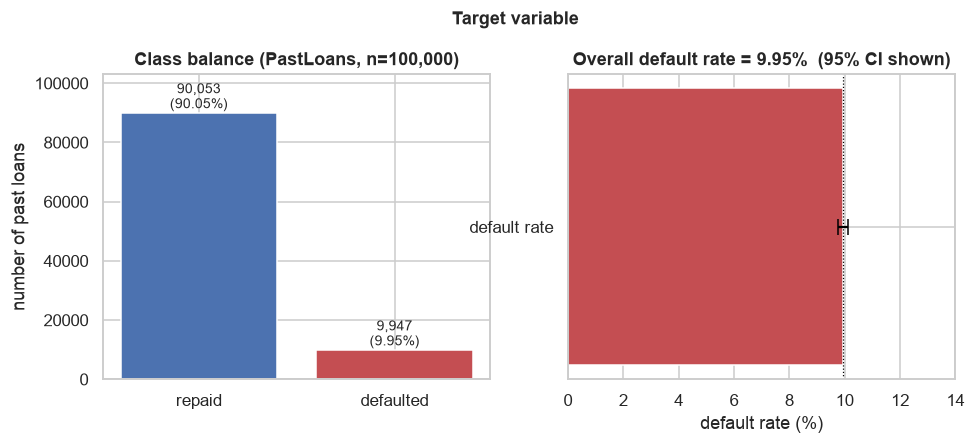

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].bar(["repaid", "defaulted"], [vc[0], vc[1]], color=["#4C72B0", "#C44E52"])
for i, v in enumerate([vc[0], vc[1]]):
    axes[0].text(i, v + 1500, f"{v:,}\n({v / len(past) * 100:.2f}%)", ha="center", fontsize=9)
axes[0].set_ylim(0, 103000)
axes[0].set_ylabel("number of past loans")
axes[0].set_title("Class balance (PastLoans, n=100,000)")

axes[1].barh(["default rate"], [overall_rate * 100], color="#C44E52", height=0.4)
axes[1].errorbar([overall_rate * 100], [0], xerr=[[(overall_rate - lo) * 100], [(hi - overall_rate) * 100]],
                 fmt="none", ecolor="black", capsize=5)
axes[1].axvline(overall_rate * 100, color="black", lw=0.8, ls=":")
axes[1].set_xlim(0, 14)
axes[1].set_xlabel("default rate (%)")
axes[1].set_title(f"Overall default rate = {overall_rate * 100:.2f}%  (95% CI shown)")

fig.suptitle("Target variable", y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig01_target_balance.png")
plt.show()

---

## 3. Distribution of each variable on its own

### 3.1 Categorical variables, in both files

Plotted side by side so that any population drift between past loans and new applicants would be
visible immediately.

saved fig02_categorical_distributions.png


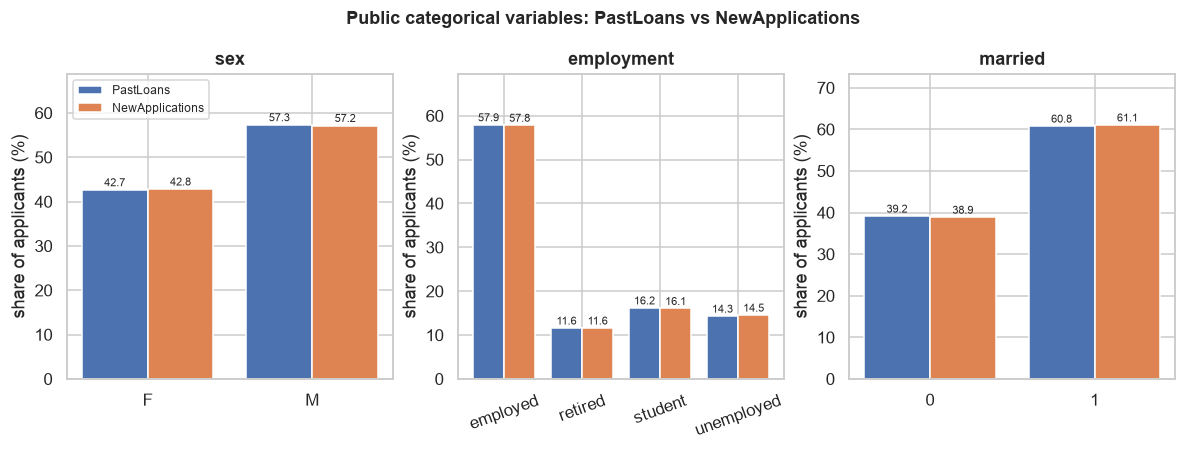

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["sex", "employment", "married"]):
    a = (past[col].value_counts(normalize=True).sort_index() * 100)
    b = (new[col].value_counts(normalize=True).sort_index() * 100)
    x = np.arange(len(a))
    ax.bar(x - 0.2, a.to_numpy(), 0.4, label="PastLoans", color="#4C72B0")
    ax.bar(x + 0.2, b.to_numpy(), 0.4, label="NewApplications", color="#DD8452")
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in a.index], rotation=20 if col == "employment" else 0)
    ax.set_ylabel("share of applicants (%)")
    ax.set_title(col)
    for xi, (va, vb) in enumerate(zip(a.to_numpy(), b.to_numpy())):
        ax.text(xi - 0.2, va + 0.8, f"{va:.1f}", ha="center", fontsize=7.5)
        ax.text(xi + 0.2, vb + 0.8, f"{vb:.1f}", ha="center", fontsize=7.5)
    ax.set_ylim(0, max(a.max(), b.max()) * 1.2)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Public categorical variables: PastLoans vs NewApplications", y=1.04,
             fontsize=12, fontweight="bold")
savefig(fig, "fig02_categorical_distributions.png")
plt.show()

### 3.2 Income

Income is extremely right-skewed and has two special features: a large spike at exactly 0 and a
top-code at €1M. Both are shown explicitly rather than hidden by axis limits.

In [12]:
inc = past["income"]
print("--- income, PastLoans ---")
print(inc.describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99, .999]).round(1).to_string())
print()
print(f"skewness (raw)        : {inc.skew():.2f}")
print(f"kurtosis (raw)        : {inc.kurt():.2f}")
print(f"skewness of log1p     : {np.log1p(inc).skew():.2f}")
print(f"skewness of log1p, income>0 only: {np.log1p(inc[inc > 0]).skew():.2f}")
print()
print(f"income == 0           : {int((inc == 0).sum()):,} ({pct((inc == 0).mean())})")
print(f"income == €1M top-code: {int((inc == INCOME_TOPCODE).sum())} ({pct((inc == INCOME_TOPCODE).mean(), 3)})")
print(f"mean €{inc.mean():,.0f} vs median €{inc.median():,.0f}  -> mean is {inc.mean() / inc.median():.1f}x the median")
print()
print("A raw skew near 12 is severe. log1p brings it close to symmetric only once the structural")
print("zeros are set aside (see below), which is why the zeros need their own treatment.")

--- income, PastLoans ---
count     100000.0
mean       18646.3
std        48178.2
min            0.0
1%             0.0
5%             0.0
25%         5385.0
50%         9370.0
75%        17474.2
90%        34573.2
95%        56786.2
99%       179540.5
99.9%     805329.6
max      1000000.0

skewness (raw)        : 11.94
kurtosis (raw)        : 193.68
skewness of log1p     : -1.56
skewness of log1p, income>0 only: 0.90

income == 0           : 17,035 (17.04%)
income == €1M top-code: 71 (0.071%)
mean €18,646 vs median €9,370  -> mean is 2.0x the median

A raw skew near 12 is severe. log1p brings it close to symmetric only once the structural
zeros are set aside (see below), which is why the zeros need their own treatment.


saved fig03_income_distribution.png


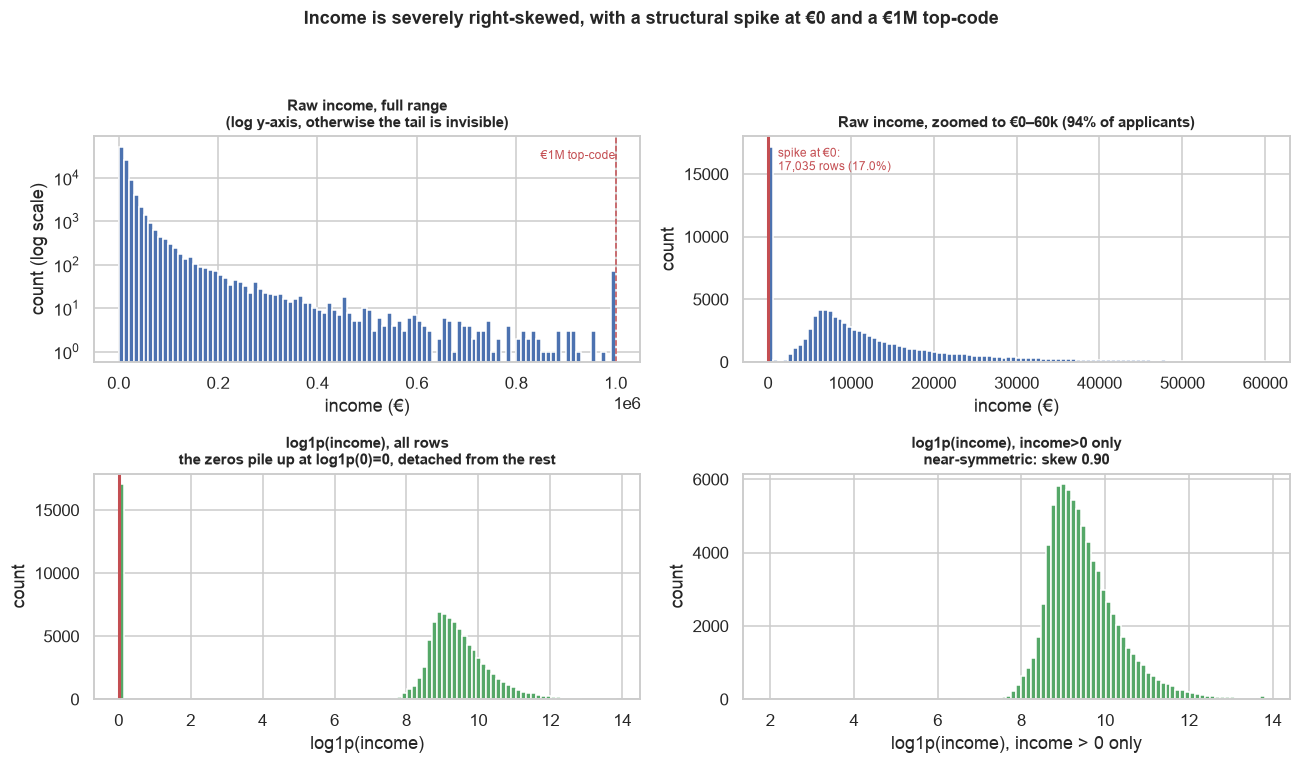

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

ax = axes[0, 0]
ax.hist(inc, bins=100, color="#4C72B0")
ax.set_yscale("log")
ax.set_xlabel("income (€)"); ax.set_ylabel("count (log scale)")
ax.set_title("Raw income, full range\n(log y-axis, otherwise the tail is invisible)", fontsize=10)
ax.axvline(INCOME_TOPCODE, color="#C44E52", ls="--", lw=1)
ax.text(INCOME_TOPCODE, ax.get_ylim()[1] * 0.3, " €1M top-code", color="#C44E52", fontsize=8, ha="right")

ax = axes[0, 1]
ax.hist(inc[inc <= 60000], bins=100, color="#4C72B0")
ax.set_xlabel("income (€)"); ax.set_ylabel("count")
ax.set_title("Raw income, zoomed to €0–60k (94% of applicants)", fontsize=10)
ax.axvline(0, color="#C44E52", lw=2)
ax.text(1200, ax.get_ylim()[1] * 0.85, f"spike at €0:\n{int((inc == 0).sum()):,} rows ({pct((inc == 0).mean(), 1)})",
        color="#C44E52", fontsize=8)

ax = axes[1, 0]
ax.hist(np.log1p(inc), bins=100, color="#55A868")
ax.set_xlabel("log1p(income)"); ax.set_ylabel("count")
ax.set_title("log1p(income), all rows\nthe zeros pile up at log1p(0)=0, detached from the rest", fontsize=10)
ax.axvline(0, color="#C44E52", lw=2)

ax = axes[1, 1]
ax.hist(np.log1p(inc[inc > 0]), bins=100, color="#55A868")
ax.set_xlabel("log1p(income), income > 0 only"); ax.set_ylabel("count")
ax.set_title(f"log1p(income), income>0 only\nnear-symmetric: skew {np.log1p(inc[inc > 0]).skew():.2f}", fontsize=10)

fig.suptitle("Income is severely right-skewed, with a structural spike at €0 and a €1M top-code",
             y=0.99, fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
savefig(fig, "fig03_income_distribution.png")
plt.show()

In [14]:
print("--- who has income == 0? ---")
t = past.assign(inc0=past["income"].eq(0)).groupby("employment").agg(
    n=("inc0", "size"), n_income0=("inc0", "sum"), share_income0=("inc0", "mean"))
t["share_income0"] = (t["share_income0"] * 100).round(2)
print(t.to_string())
print()
print("EVIDENCE: income == 0 occurs ONLY among students (62.8%) and the unemployed (48.0%),")
print("and never for employed or retired applicants. So it is a structural zero -- 'this person")
print("has no earned income' -- not a missing-value placeholder.")
print()
print("CONSEQUENCE for feature engineering: log(income) is undefined for 17% of rows, so any log")
print("transform needs log1p (or an explicit zero flag). See section 5.3 for whether the zero")
print("carries risk information beyond employment status.")

--- who has income == 0? ---
                n  n_income0  share_income0
employment                                 
employed    57936          0           0.00
retired     11582          0           0.00
student     16183      10169          62.84
unemployed  14299       6866          48.02

EVIDENCE: income == 0 occurs ONLY among students (62.8%) and the unemployed (48.0%),
and never for employed or retired applicants. So it is a structural zero -- 'this person
has no earned income' -- not a missing-value placeholder.

CONSEQUENCE for feature engineering: log(income) is undefined for 17% of rows, so any log
transform needs log1p (or an explicit zero flag). See section 5.3 for whether the zero
carries risk information beyond employment status.


### 3.3 The three signals

Each lender sees its own private signal, coded on `[0, 1]`. The marginal distributions are almost
indistinguishable across the three lenders — consistent with three draws from the same mechanism.

In [15]:
print("--- signal summary statistics ---")
desc = past[SIGNALS].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["skew"] = past[SIGNALS].skew()
desc["share_zero_%"] = [(past[c] == 0).mean() * 100 for c in SIGNALS]
print(desc.round(4).to_string())
print()
print("--- same statistics for signal3 in NewApplications ---")
d2 = new[["signal3"]].describe(percentiles=[.05, .25, .5, .75, .95]).T
d2["skew"] = new["signal3"].skew()
d2["share_zero_%"] = (new["signal3"] == 0).mean() * 100
print(d2.round(4).to_string())

--- signal summary statistics ---
            count    mean     std  min   5%     25%     50%     75%     95%  max    skew  share_zero_%
signal1  100000.0  0.4177  0.3253  0.0  0.0  0.0646  0.4482  0.6960  0.9200  1.0  0.0616        20.837
signal2  100000.0  0.4157  0.3251  0.0  0.0  0.0626  0.4446  0.6948  0.9190  1.0  0.0682        20.897
signal3  100000.0  0.4149  0.3251  0.0  0.0  0.0605  0.4409  0.6924  0.9199  1.0  0.0730        21.055

--- same statistics for signal3 in NewApplications ---
            count    mean     std  min   5%     25%     50%     75%   95%  max    skew  share_zero_%
signal3  100000.0  0.4162  0.3248  0.0  0.0  0.0626  0.4464  0.6943  0.92  1.0  0.0661        20.935


saved fig04_signal_distributions.png


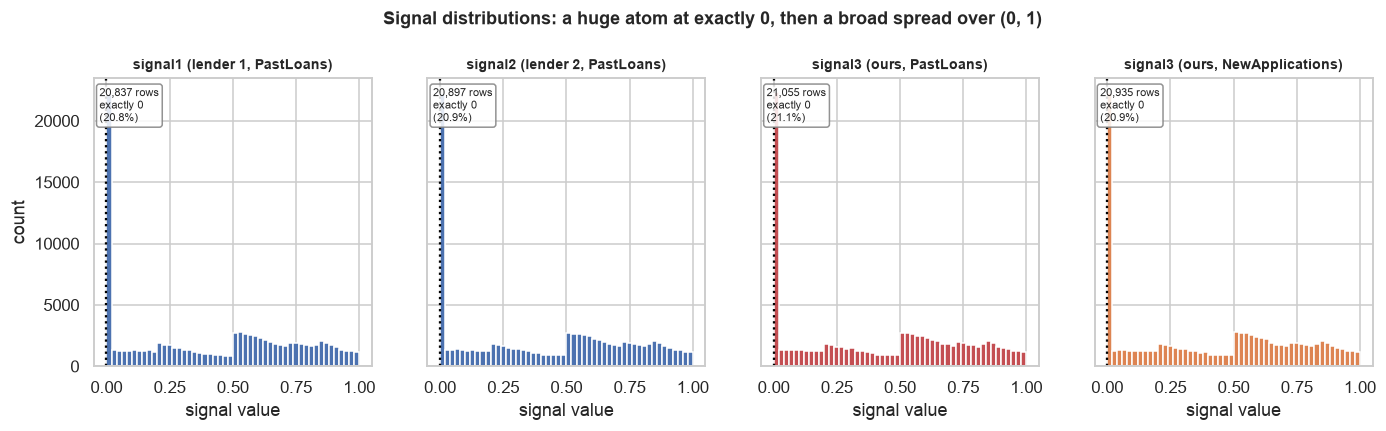

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
series = [("signal1 (lender 1, PastLoans)", past["signal1"], "#4C72B0"),
          ("signal2 (lender 2, PastLoans)", past["signal2"], "#4C72B0"),
          ("signal3 (ours, PastLoans)", past["signal3"], "#C44E52"),
          ("signal3 (ours, NewApplications)", new["signal3"], "#DD8452")]
for ax, (title, s, colr) in zip(axes, series):
    ax.hist(s, bins=50, color=colr)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("signal value")
    ax.axvline(0, color="black", lw=1.5, ls=":")
    ax.annotate(f"{int((s == 0).sum()):,} rows\nexactly 0\n({pct((s == 0).mean(), 1)})",
                xy=(0.02, 0.97), xycoords="axes fraction", va="top", fontsize=7.5,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="grey", alpha=0.85))
axes[0].set_ylabel("count")
fig.suptitle("Signal distributions: a huge atom at exactly 0, then a broad spread over (0, 1)",
             y=1.06, fontsize=12, fontweight="bold")
savefig(fig, "fig04_signal_distributions.png")
plt.show()

---

## 4. Deep dive: the mass of signals at exactly 0

About 21% of every signal is **exactly** `0`. Whether that `0` is a genuine "lowest possible
score" or a code meaning "no signal was received" changes how it should be fed to a model, so it
is worth testing properly. Sections 4.1–4.4 test the question four ways; 4.5 then measures how
much the answer changes the numbers.

### 4.1 Is 0 a separate spike, or just the bottom of a continuous distribution?

In [17]:
W = 0.005
rows = []
for nm, s in [("signal1 (past)", past["signal1"]), ("signal2 (past)", past["signal2"]),
              ("signal3 (past)", past["signal3"]), ("signal3 (new)", new["signal3"])]:
    n0 = int((s == 0).sum())
    first = int(((s > 0) & (s <= W)).sum())
    near = [int(((s > W * i) & (s <= W * (i + 1))).sum()) for i in range(10)]
    smallest_pos = s[s > 0].min()
    rows.append({"series": nm, "count at exactly 0": n0, f"count in (0, {W}]": first,
                 "mean count per 0.005 bin over (0, 0.05]": int(np.mean(near)),
                 "ratio (0 vs first bin)": round(n0 / first, 1),
                 "smallest positive value": f"{smallest_pos:.2e}"})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("EVIDENCE 1 -- the atom is ~60x the adjacent bin. If 0 were simply the low end of a")
print("continuous distribution, the count at a single point would be comparable to, not 60 times,")
print("the count in a neighbouring interval of positive width.")
print()
print("EVIDENCE 2 -- there is no gap. The smallest positive values are of order 1e-5, so the")
print("continuous part runs smoothly down towards 0 while a large point mass sits exactly on 0.")
print("A continuous density plus a separate atom is a mixture, not one smooth distribution.")

        series  count at exactly 0  count in (0, 0.005]  mean count per 0.005 bin over (0, 0.05]  ratio (0 vs first bin) smallest positive value
signal1 (past)               20837                  312                                      325                    66.8                8.16e-06
signal2 (past)               20897                  339                                      328                    61.6                3.22e-05
signal3 (past)               21055                  347                                      329                    60.7                1.47e-05
 signal3 (new)               20935                  361                                      325                    58.0                5.73e-06

EVIDENCE 1 -- the atom is ~60x the adjacent bin. If 0 were simply the low end of a
continuous distribution, the count at a single point would be comparable to, not 60 times,
the count in a neighbouring interval of positive width.

EVIDENCE 2 -- there is no gap. The smallest

In [18]:
print("--- density extrapolation test ---")
print("If the positive part continued through 0 as one smooth density, the expected number of")
print("observations in a narrow interval of width w at the bottom would be about w x f(0+) x n.")
print()
for c in SIGNALS:
    s = past[c]
    pos = s[s > 0]
    f0 = ((pos > 0) & (pos <= 0.05)).sum() / 0.05 / len(pos)   # density per positive observation
    for w in [0.01]:
        expected = f0 * w * len(pos)
        print(f"{c}: estimated f(0+) = {f0:.3f} | expected count in a width-{w} interval = {expected:,.0f} "
              f"| actual atom at 0 = {int((s == 0).sum()):,}  -> {int((s == 0).sum()) / expected:.0f}x too many")
print()
print("INTERPRETATION (ours): the atom is far too large to be the tail of the continuous part.")
print("CAVEAT: this test alone cannot distinguish a 'no signal' code from a signal that was")
print("CLIPPED at 0 (e.g. signal = max(0, latent)), because clipping also produces an atom of")
print("size P(latent <= 0) on top of a smooth density. Section 4.4 is what separates the two.")

--- density extrapolation test ---
If the positive part continued through 0 as one smooth density, the expected number of
observations in a narrow interval of width w at the bottom would be about w x f(0+) x n.

signal1: estimated f(0+) = 0.822 | expected count in a width-0.01 interval = 650 | actual atom at 0 = 20,837  -> 32x too many
signal2: estimated f(0+) = 0.831 | expected count in a width-0.01 interval = 657 | actual atom at 0 = 20,897  -> 32x too many
signal3: estimated f(0+) = 0.835 | expected count in a width-0.01 interval = 659 | actual atom at 0 = 21,055  -> 32x too many

INTERPRETATION (ours): the atom is far too large to be the tail of the continuous part.
CAVEAT: this test alone cannot distinguish a 'no signal' code from a signal that was
CLIPPED at 0 (e.g. signal = max(0, latent)), because clipping also produces an atom of
size P(latent <= 0) on top of a smooth density. Section 4.4 is what separates the two.


saved fig05_signal_zero_spike.png


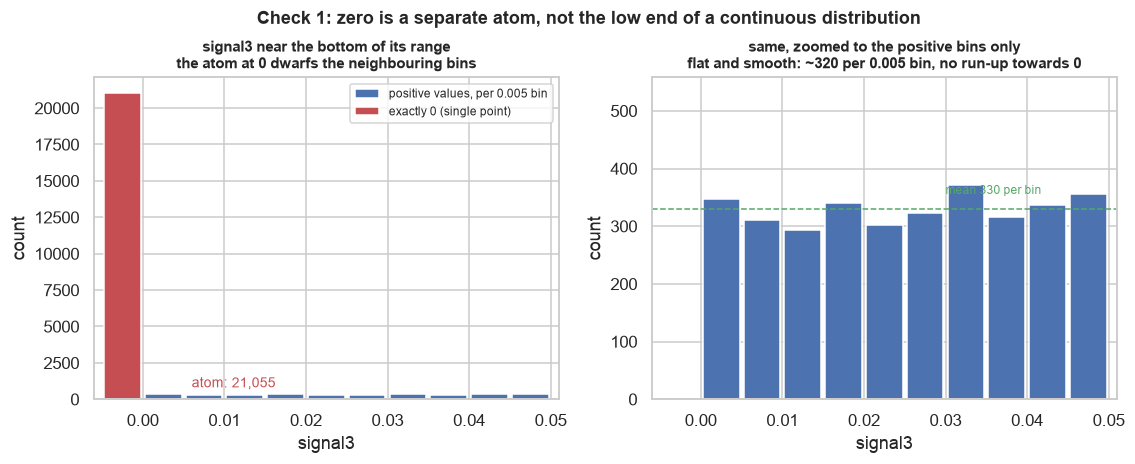

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

ax = axes[0]
edges = np.arange(0, 0.05 + 1e-9, 0.005)
counts, _ = np.histogram(past["signal3"][past["signal3"] > 0], bins=edges)
ax.bar(edges[:-1] + 0.0025, counts, width=0.0045, color="#4C72B0", label="positive values, per 0.005 bin")
ax.bar([-0.0025], [int((past["signal3"] == 0).sum())], width=0.0045, color="#C44E52",
       label="exactly 0 (single point)")
ax.set_xlim(-0.006, 0.051)
ax.set_xlabel("signal3"); ax.set_ylabel("count")
ax.set_title("signal3 near the bottom of its range\nthe atom at 0 dwarfs the neighbouring bins", fontsize=10)
ax.legend(fontsize=8)
ax.text(0.006, counts.max() * 2.2, f"atom: {int((past['signal3'] == 0).sum()):,}", color="#C44E52", fontsize=9)

ax = axes[1]
ax.bar(edges[:-1] + 0.0025, counts, width=0.0045, color="#4C72B0")
ax.set_xlim(-0.006, 0.051)
ax.set_ylim(0, counts.max() * 1.5)
ax.set_xlabel("signal3"); ax.set_ylabel("count")
ax.set_title("same, zoomed to the positive bins only\nflat and smooth: ~320 per 0.005 bin, no run-up towards 0", fontsize=10)
ax.axhline(counts.mean(), color="#55A868", ls="--", lw=1)
ax.text(0.03, counts.mean() * 1.08, f"mean {counts.mean():.0f} per bin", color="#55A868", fontsize=8)

fig.suptitle("Check 1: zero is a separate atom, not the low end of a continuous distribution",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig05_signal_zero_spike.png")
plt.show()

### 4.2 Do the three lenders' zeros coincide?

If `0` meant "this applicant is unscoreable", all three lenders would tend to be blank on the same
applicants. If each lender independently fails to get a signal, the zeros should be close to
independent across lenders.

In [20]:
Z = (past[SIGNALS] == 0)
p_marg = Z.mean()
print("--- marginal P(signal_i == 0) ---")
print((p_marg * 100).round(2).to_string())
print()
k = Z.sum(axis=1)
obs = k.value_counts().sort_index()
pbar = float(p_marg.mean())
exp = pd.Series([stats.binom.pmf(i, 3, pbar) * len(past) for i in range(4)], index=range(4))
tab = pd.DataFrame({"observed": obs, "expected if independent": exp.round(0),
                    "obs / exp": (obs / exp).round(3)})
tab.index.name = "no. of signals equal to 0"
print(f"--- how many of the three signals are zero (using pbar = {pbar:.4f}) ---")
print(tab.to_string())
chi2 = float((((obs - exp) ** 2) / exp).sum())
print(f"\nchi-square vs independence = {chi2:.1f} on 3 df, p = {stats.chi2.sf(chi2, 3):.2e}")
print()
print("--- phi (Pearson) correlation between the zero indicators ---")
print(Z.astype(int).corr().round(4).to_string())
print()
print("EVIDENCE: the pairwise correlations are tiny (0.022 to 0.034) and the observed counts are")
print("close to the independent-binomial expectation -- but not equal to it: triple zeros are")
print(f"{obs[3]:,} against {exp[3]:.0f} expected, and the chi-square decisively rejects exact")
print("independence. So the zeros are MOSTLY lender-specific, with a small shared component.")
print("Section 4.3 shows that the shared component is explained by the public variables.")

--- marginal P(signal_i == 0) ---
signal1    20.84
signal2    20.90
signal3    21.06

--- how many of the three signals are zero (using pbar = 0.2093) ---
                           observed  expected if independent  obs / exp
no. of signals equal to 0                                              
0                             50500                  49436.0      1.022
1                             37469                  39256.0      0.954
2                             10773                  10391.0      1.037
3                              1258                    917.0      1.372

chi-square vs independence = 245.3 on 3 df, p = 6.81e-53

--- phi (Pearson) correlation between the zero indicators ---
         signal1  signal2  signal3
signal1   1.0000   0.0225   0.0336
signal2   0.0225   1.0000   0.0288
signal3   0.0336   0.0288   1.0000

EVIDENCE: the pairwise correlations are tiny (0.022 to 0.034) and the observed counts are
close to the independent-binomial expectation -- but not equa

saved fig06_signal_zero_cooccurrence.png


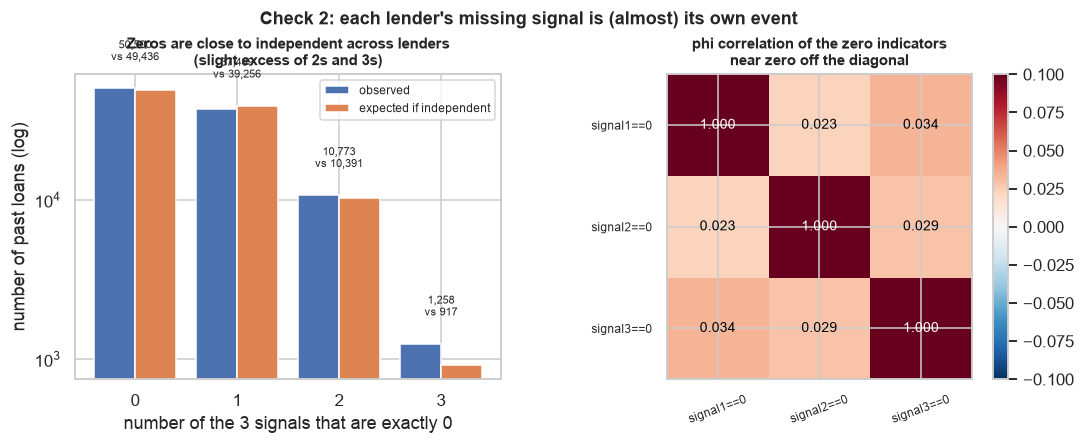

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
x = np.arange(4)
ax.bar(x - 0.2, obs.reindex(range(4), fill_value=0).to_numpy(), 0.4, label="observed", color="#4C72B0")
ax.bar(x + 0.2, exp.to_numpy(), 0.4, label="expected if independent", color="#DD8452")
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xlabel("number of the 3 signals that are exactly 0")
ax.set_ylabel("number of past loans (log)")
ax.set_title("Zeros are close to independent across lenders\n(slight excess of 2s and 3s)", fontsize=10)
ax.legend(fontsize=8)
for xi in x:
    ax.text(xi, max(obs.get(xi, 0), exp[xi]) * 1.5, f"{obs.get(xi, 0):,}\nvs {exp[xi]:,.0f}",
            ha="center", fontsize=7)

ax = axes[1]
corr = Z.astype(int).corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-0.1, vmax=0.1)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{c}==0" for c in SIGNALS], fontsize=8, rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels([f"{c}==0" for c in SIGNALS], fontsize=8)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.3f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
ax.set_title("phi correlation of the zero indicators\nnear zero off the diagonal", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("Check 2: each lender's missing signal is (almost) its own event",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig06_signal_zero_cooccurrence.png")
plt.show()

### 4.3 Is the zero related to the applicant's observable characteristics?

If `0` were a purely random technical failure it would be unrelated to who the applicant is. It
is not.

In [22]:
work = past.assign(**{f"z{i}": (past[f"signal{i}"] == 0).astype(int) for i in (1, 2, 3)})

for v in ["sex", "employment", "married"]:
    t = work.groupby(v).agg(n=("z3", "size"), P_z1=("z1", "mean"), P_z2=("z2", "mean"), P_z3=("z3", "mean"))
    for c in ["P_z1", "P_z2", "P_z3"]:
        t[c] = (t[c] * 100).round(2)
    print(f"--- P(signal_i == 0) by {v}, in % ---")
    print(t.to_string())
    print()

work["income_decile"] = pd.qcut(work["income"].rank(method="first"), 10,
                                labels=[f"d{i}" for i in range(1, 11)])
t = work.groupby("income_decile", observed=True).agg(
    n=("z3", "size"), median_income=("income", "median"), P_z3=("z3", "mean"))
t["P_z3"] = (t["P_z3"] * 100).round(2)
print("--- P(signal3 == 0) by income decile, in % ---")
print(t.to_string())
print()
print("EVIDENCE: the probability of a zero signal varies a lot by employment -- retired 36.5%,")
print("employed 21.2%, unemployed 23.0%, student 7.9% -- and also by marital status (18.3% vs")
print("22.9%) and across the bottom income deciles (14.0% in d1 vs ~22% elsewhere).")
print()
print("INTERPRETATION (ours): the zeros are not completely at random; they are related to")
print("observable characteristics. That also explains the small shared component found in 4.2:")
print("all three lenders are more likely to be blank on the same retired, married applicant.")
print("Practical note: a 'signal was zero' flag therefore carries a little information about WHO")
print("the applicant is, on top of the information lost about their risk.")

--- P(signal_i == 0) by sex, in % ---
         n   P_z1   P_z2   P_z3
sex                            
F    42669  21.05  21.38  21.11
M    57331  20.68  20.54  21.01

--- P(signal_i == 0) by employment, in % ---
                n   P_z1   P_z2   P_z3
employment                            
employed    57936  20.99  20.97  21.18
retired     11582  36.30  35.93  36.50
student     16183   7.73   7.98   7.85
unemployed  14299  22.53  23.04  22.97

--- P(signal_i == 0) by married, in % ---
             n   P_z1   P_z2   P_z3
married                            
0        39178  17.87  18.02  18.25
1        60822  22.75  22.75  22.86

--- P(signal3 == 0) by income decile, in % ---
                   n  median_income   P_z3
income_decile                             
d1             10000            0.0  13.97
d2             10000            0.0  18.94
d3             10000         5385.0  24.04
d4             10000         6903.0  22.84
d5             10000         8458.0  21.86
d6             100

saved fig07_pzero_by_group.png


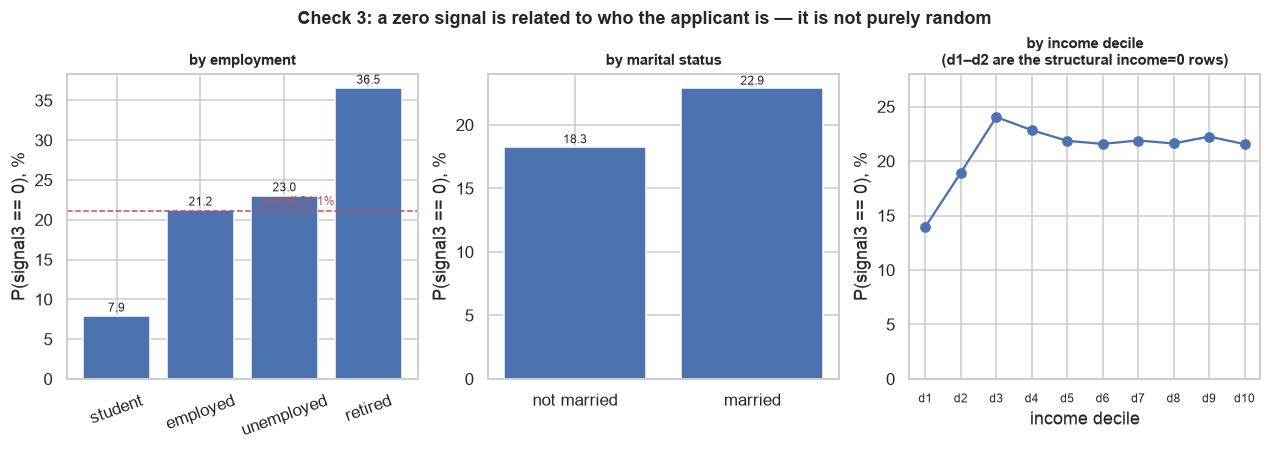

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

ax = axes[0]
t = work.groupby("employment")["z3"].mean().sort_values() * 100
ax.bar(t.index, t.to_numpy(), color="#4C72B0")
ax.axhline((past["signal3"] == 0).mean() * 100, color="#C44E52", ls="--", lw=1)
ax.text(2.6, (past["signal3"] == 0).mean() * 100 + 0.8, "overall 21.1%", color="#C44E52", fontsize=8, ha="right")
ax.set_ylabel("P(signal3 == 0), %"); ax.set_title("by employment", fontsize=10)
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(t.to_numpy()):
    ax.text(i, v + 0.6, f"{v:.1f}", ha="center", fontsize=8)

ax = axes[1]
t = work.groupby("married")["z3"].mean() * 100
ax.bar(["not married", "married"], t.to_numpy(), color="#4C72B0")
ax.set_ylabel("P(signal3 == 0), %"); ax.set_title("by marital status", fontsize=10)
for i, v in enumerate(t.to_numpy()):
    ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)

ax = axes[2]
t = work.groupby("income_decile", observed=True)["z3"].mean() * 100
ax.plot(range(1, 11), t.to_numpy(), "o-", color="#4C72B0")
ax.set_xticks(range(1, 11)); ax.set_xticklabels([f"d{i}" for i in range(1, 11)], fontsize=8)
ax.set_xlabel("income decile"); ax.set_ylabel("P(signal3 == 0), %")
ax.set_title("by income decile\n(d1–d2 are the structural income=0 rows)", fontsize=10)
ax.set_ylim(0, 28)

fig.suptitle("Check 3: a zero signal is related to who the applicant is — it is not purely random",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig07_pzero_by_group.png")
plt.show()

### 4.4 The decisive check: what is the default rate of the zero group?

This is what separates the two competing explanations.

* If `0` were a **clipped low score** (`signal = max(0, latent)`), the zero group would be the
  *riskiest* group of all — at least as risky as the lowest positive decile.
* If `0` means **"no signal received"**, the zero group should look like a roughly *average* slice
  of the population, because the applicants in it were never scored.

In [24]:
print("--- default rate: signal exactly 0 vs strictly positive, with 95% Wilson CIs ---")
for c in SIGNALS:
    g = rate_by(past.assign(grp=np.where(past[c] == 0, "signal == 0", "signal > 0")), "grp")
    g["rate_%"] = (g["rate"] * 100).round(3)
    g["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(g["ci_lo"], g["ci_hi"])]
    print(f"--- {c} ---")
    print(g[["n", "defaults", "rate_%", "CI_%"]].to_string())
    z0 = past.loc[past[c] == 0, "default"]
    z1 = past.loc[past[c] > 0, "default"]
    diff = z1.mean() - z0.mean()
    se = np.sqrt(z0.var(ddof=1) / len(z0) + z1.var(ddof=1) / len(z1))
    print(f"    difference (>0 minus ==0) = {diff * 100:+.2f} pp, se {se * 100:.2f} pp, z = {diff / se:+.2f}")
    print()
print(f"overall default rate for reference: {pct(past['default'].mean(), 2)}")
print()
print("--- and where does the lowest POSITIVE decile sit? ---")
for c in SIGNALS:
    b = signal_bins(past[c], q=10)
    g = rate_by(past.assign(b=b), "b")
    print(f"{c}: 'exactly 0' = {g.loc['exactly 0', 'rate'] * 100:5.2f}%  |  "
          f"q1 (lowest positive) = {g.loc['q1', 'rate'] * 100:5.2f}%  |  "
          f"q10 (highest) = {g.loc['q10', 'rate'] * 100:5.2f}%")
print()
print("EVIDENCE: the zero group defaults at 9.5-9.7%, statistically indistinguishable from the")
print("population average of 9.95% (|z| < 2 against the positive-signal group). The lowest")
print("positive decile defaults at 16-17%. If zero were a clipped low score, the zero group")
print("would sit at or above 17%, not at the population mean.")
print()
print("INTERPRETATION (ours, NOT stated in the course brief): signal == 0 reads as 'this lender")
print("received no signal for this applicant', recorded as 0. It is a MISSING-VALUE CODE on the")
print("same column as real values. OPEN QUESTION for the team/lecturer -- worth confirming,")
print("because it determines how the signals should be encoded.")

--- default rate: signal exactly 0 vs strictly positive, with 95% Wilson CIs ---
--- signal1 ---
                 n  defaults  rate_%           CI_%
grp                                                
signal == 0  20837      1977   9.488   [9.10, 9.89]
signal > 0   79163      7970  10.068  [9.86, 10.28]
    difference (>0 minus ==0) = +0.58 pp, se 0.23 pp, z = +2.53

--- signal2 ---
                 n  defaults  rate_%           CI_%
grp                                                
signal == 0  20897      2028   9.705  [9.31, 10.11]
signal > 0   79103      7919  10.011  [9.80, 10.22]
    difference (>0 minus ==0) = +0.31 pp, se 0.23 pp, z = +1.33

--- signal3 ---
                 n  defaults  rate_%           CI_%
grp                                                
signal == 0  21055      2036   9.670  [9.28, 10.08]
signal > 0   78945      7911  10.021  [9.81, 10.23]
    difference (>0 minus ==0) = +0.35 pp, se 0.23 pp, z = +1.53

overall default rate for reference: 9.95%

--- and w

signal3: 'exactly 0' =  9.67%  |  q1 (lowest positive) = 16.96%  |  q10 (highest) =  7.79%

EVIDENCE: the zero group defaults at 9.5-9.7%, statistically indistinguishable from the
population average of 9.95% (|z| < 2 against the positive-signal group). The lowest
positive decile defaults at 16-17%. If zero were a clipped low score, the zero group
would sit at or above 17%, not at the population mean.

INTERPRETATION (ours, NOT stated in the course brief): signal == 0 reads as 'this lender
received no signal for this applicant', recorded as 0. It is a MISSING-VALUE CODE on the
same column as real values. OPEN QUESTION for the team/lecturer -- worth confirming,
because it determines how the signals should be encoded.


One composition worry is worth ruling out. Retired applicants are blank far more often (36.5%)
and are also below-average risk (8.95% vs 9.95% overall), so the zero group's average risk could
in principle be an artefact of its mix. The test below repeats the comparison **inside each employment category**, which removes that
channel.

In [25]:
print("--- within each employment category: does the zero group match its own base rate? ---")
print()
rows = []
for emp in ["employed", "retired", "student", "unemployed"]:
    sub = past[past["employment"] == emp]
    z = sub.loc[sub["signal3"] == 0, "default"]
    pos = sub[sub["signal3"] > 0]
    q1 = pos.assign(q=pd.qcut(pos["signal3"], 10, labels=False)).query("q == 0")["default"]
    lo, hi = wilson_ci(int(z.sum()), len(z))
    rows.append({"employment": emp, "group base rate %": round(sub["default"].mean() * 100, 2),
                 "signal3 == 0 rate %": round(z.mean() * 100, 2), "n (zeros)": len(z),
                 "95% CI of zero group": f"[{lo * 100:.2f}, {hi * 100:.2f}]",
                 "signal3 > 0 rate %": round(pos["default"].mean() * 100, 2),
                 "q1 of positives %": round(q1.mean() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("EVIDENCE: in all four categories the zero group lands on its own group's base rate, and")
print("every group's base rate is inside the zero group's 95% CI. Meanwhile the lowest positive")
print("decile within the same category runs at 14.1% / 17.4% / 21.7% / 26.5% -- far above.")
print("So the result is not a composition artefact: it holds with employment held fixed.")
print()
print("This is the single strongest piece of evidence that the zeros are 'no signal received'")
print("rather than a genuine low score. It is still an inference, not a documented fact.")

--- within each employment category: does the zero group match its own base rate? ---

employment  group base rate %  signal3 == 0 rate %  n (zeros) 95% CI of zero group  signal3 > 0 rate %  q1 of positives %
  employed               7.93                 8.28      12272         [7.80, 8.78]                7.84              14.08
   retired               8.95                 9.04       4227         [8.21, 9.94]                8.91              17.39
   student              12.85                13.30       1271       [11.54, 15.27]               12.82              21.65
unemployed              15.62                14.28       3285       [13.12, 15.52]               16.03              26.50

EVIDENCE: in all four categories the zero group lands on its own group's base rate, and
every group's base rate is inside the zero group's 95% CI. Meanwhile the lowest positive
decile within the same category runs at 14.1% / 17.4% / 21.7% / 26.5% -- far above.
So the result is not a composition artefa

saved fig08_default_by_signal_bins.png


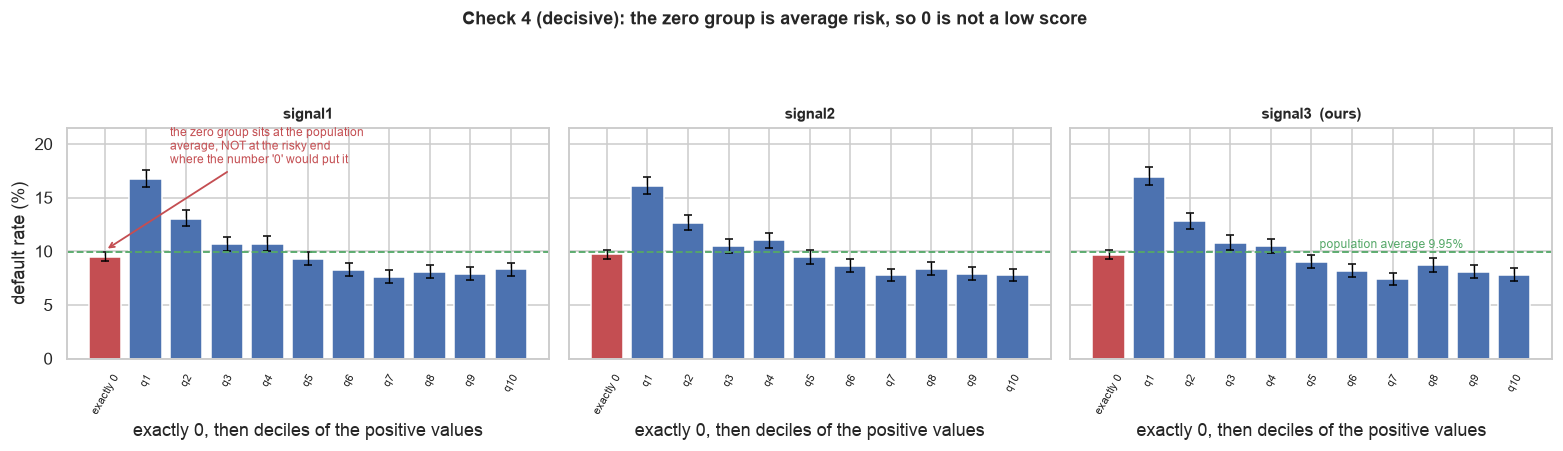

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4), sharey=True)
for ax, c in zip(axes, SIGNALS):
    b = signal_bins(past[c], q=10)
    g = rate_by(past.assign(b=b), "b")
    xs = np.arange(len(g))
    colors = ["#C44E52"] + ["#4C72B0"] * (len(g) - 1)
    ax.bar(xs, g["rate"] * 100, color=colors)
    ax.errorbar(xs, g["rate"] * 100,
                yerr=[(g["rate"] - g["ci_lo"]) * 100, (g["ci_hi"] - g["rate"]) * 100],
                fmt="none", ecolor="black", capsize=2.5, lw=0.9)
    ax.axhline(past["default"].mean() * 100, color="#55A868", ls="--", lw=1.2)
    ax.set_xticks(xs); ax.set_xticklabels(g.index, rotation=60, fontsize=7.5)
    ax.set_title(f"{c}{'  (ours)' if c == OUR_SIGNAL else ''}", fontsize=10)
    ax.set_xlabel("exactly 0, then deciles of the positive values")
axes[0].set_ylabel("default rate (%)")
axes[0].set_ylim(0, 21.5)
axes[2].text(5.2, past["default"].mean() * 100 + 0.35, "population average 9.95%",
             color="#55A868", fontsize=8)
axes[0].annotate("the zero group sits at the population\naverage, NOT at the risky end\nwhere the number '0' would put it",
                 xy=(0, 10.1), xytext=(1.6, 18.2), fontsize=8, color="#C44E52",
                 arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1.2))
fig.suptitle("Check 4 (decisive): the zero group is average risk, so 0 is not a low score",
             y=1.02, fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
savefig(fig, "fig08_default_by_signal_bins.png")
plt.show()

### 4.5 How much does the coding choice change the numbers?

Univariate AUC, oriented so that higher = more predictive; because a *higher* signal means *lower*
risk, the score used is `-signal`.

The comparison that matters is **like-for-like: the same 100,000 rows, the same target, the same
variable — only the number written in the zero cells changes.** Coding A leaves the zeros as the
literal value `0`, which ranks those applicants as the riskiest in the file. Codings B and C
replace them with a neutral central value (the median or mean of the present values), which ranks
them in the middle. Nothing is dropped, so the two AUCs are directly comparable, and the
difference can be bootstrapped as a paired quantity on resampled rows.

In [27]:
rows = []
for c in SIGNALS:
    s = past[c]
    present = s > 0
    med, mean = s[present].median(), s[present].mean()
    a_zero = roc_auc_score(past["default"], -s)
    a_med = roc_auc_score(past["default"], -s.where(present, med))
    a_mean = roc_auc_score(past["default"], -s.where(present, mean))
    rows.append({"signal": c, "n rows": len(past),
                 "A: zeros as 0": round(a_zero, 4),
                 "B: zeros as median present": round(a_med, 4),
                 "C: zeros as mean present": round(a_mean, 4),
                 "B - A": round(a_med - a_zero, 4)})
print("--- same 100,000 rows, same target, only the zero cells recoded ---")
print(pd.DataFrame(rows).to_string(index=False))

--- same 100,000 rows, same target, only the zero cells recoded ---
 signal  n rows  A: zeros as 0  B: zeros as median present  C: zeros as mean present  B - A
signal1  100000         0.5429                      0.5670                    0.5675 0.0240
signal2  100000         0.5425                      0.5631                    0.5637 0.0206
signal3  100000         0.5446                      0.5663                    0.5672 0.0217


In [28]:
print("--- paired bootstrap of the gain B - A (same rows resampled together, seed 42) ---")
B_REPS = 400
n = len(past)
y_boot = past["default"].to_numpy()
boot = {}
for c in SIGNALS:
    s = past[c].to_numpy()
    present = s > 0
    s_recoded = np.where(present, s, np.median(s[present]))
    diffs = []
    for _ in range(B_REPS):
        idx = rng.integers(0, n, n)
        yy = y_boot[idx]
        if yy.min() == yy.max():
            continue
        diffs.append(roc_auc_score(yy, -s_recoded[idx]) - roc_auc_score(yy, -s[idx]))
    d = np.array(diffs)
    boot[c] = d
    print(f"  {c}: mean gain {d.mean():+.4f}, 95% bootstrap CI "
          f"[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]  (B={len(d)} resamples)")
print()
print("EVIDENCE: on identical rows, moving the zeros from the bottom of the ranking to a neutral")
print("middle value is worth about +0.021 to +0.024 AUC, and the bootstrap interval excludes zero")
print("for all three signals. The sign and rough size of the effect are therefore solid.")
print()
print("What this does NOT settle: the median is an arbitrary stand-in, so these numbers measure")
print("the cost of the WORST coding, not the gain from the BEST one. A separate missing-indicator")
print("column, or leaving the 0 in place for a tree model to split off by itself, could do better")
print("or worse. The choice between those options belongs to feature engineering.")

--- paired bootstrap of the gain B - A (same rows resampled together, seed 42) ---


  signal1: mean gain +0.0242, 95% bootstrap CI [+0.0195, +0.0288]  (B=400 resamples)


  signal2: mean gain +0.0206, 95% bootstrap CI [+0.0160, +0.0253]  (B=400 resamples)


  signal3: mean gain +0.0219, 95% bootstrap CI [+0.0173, +0.0264]  (B=400 resamples)

EVIDENCE: on identical rows, moving the zeros from the bottom of the ranking to a neutral
middle value is worth about +0.021 to +0.024 AUC, and the bootstrap interval excludes zero
for all three signals. The sign and rough size of the effect are therefore solid.

What this does NOT settle: the median is an arbitrary stand-in, so these numbers measure
the cost of the WORST coding, not the gain from the BEST one. A separate missing-indicator
column, or leaving the 0 in place for a tree model to split off by itself, could do better
or worse. The choice between those options belongs to feature engineering.


A different question, needing a different row set: **how good is a signal when it is actually
present?** That is measured only on the rows where the signal is positive, so it is *not*
comparable with the table above — fewer rows, a different applicant mix.

In [29]:
for c in SIGNALS:
    present = past[c] > 0
    print(f"  {c}: AUC on the {int(present.sum()):,} rows where the signal is present = "
          f"{roc_auc_score(past.loc[present, 'default'], -past.loc[present, c]):.4f}")
print()
print("These sit near 0.572-0.576, above every whole-file figure above, which is consistent with")
print("the zeros being uninformative rows rather than informative low scores.")

  signal1: AUC on the 79,163 rows where the signal is present = 0.5762
  signal2: AUC on the 79,103 rows where the signal is present = 0.5720
  signal3: AUC on the 78,945 rows where the signal is present = 0.5763

These sit near 0.572-0.576, above every whole-file figure above, which is consistent with
the zeros being uninformative rows rather than informative low scores.


---

## 5. Each variable against `default`

### 5.1 Categorical variables

Group sizes are large enough throughout that the confidence intervals are narrow — the half-widths
below run from ±0.22 to ±0.60 percentage points — so the differences are real rather than noise.

In [30]:
for v in ["sex", "employment", "married"]:
    g = rate_by(past, v).sort_values("rate")
    g["rate_%"] = (g["rate"] * 100).round(2)
    g["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(g["ci_lo"], g["ci_hi"])]
    g["+/- pp"] = g["ci_pm_pp"].round(2)
    print(f"--- default rate by {v} (sorted by risk) ---")
    print(g[["n", "defaults", "rate_%", "CI_%", "+/- pp"]].to_string())
    print()

--- default rate by sex (sorted by risk) ---
         n  defaults  rate_%            CI_%  +/- pp
sex                                                 
M    57331      5394    9.41    [9.17, 9.65]    0.24
F    42669      4553   10.67  [10.38, 10.97]    0.29

--- default rate by employment (sorted by risk) ---
                n  defaults  rate_%            CI_%  +/- pp
employment                                                 
employed    57936      4596    7.93    [7.72, 8.16]    0.22
retired     11582      1037    8.95    [8.45, 9.49]    0.52
student     16183      2080   12.85  [12.35, 13.38]    0.52
unemployed  14299      2234   15.62  [15.04, 16.23]    0.60

--- default rate by married (sorted by risk) ---
             n  defaults  rate_%            CI_%  +/- pp
married                                                 
1        60822      5721    9.41    [9.18, 9.64]    0.23
0        39178      4226   10.79  [10.48, 11.10]    0.31



saved fig09_default_by_category.png


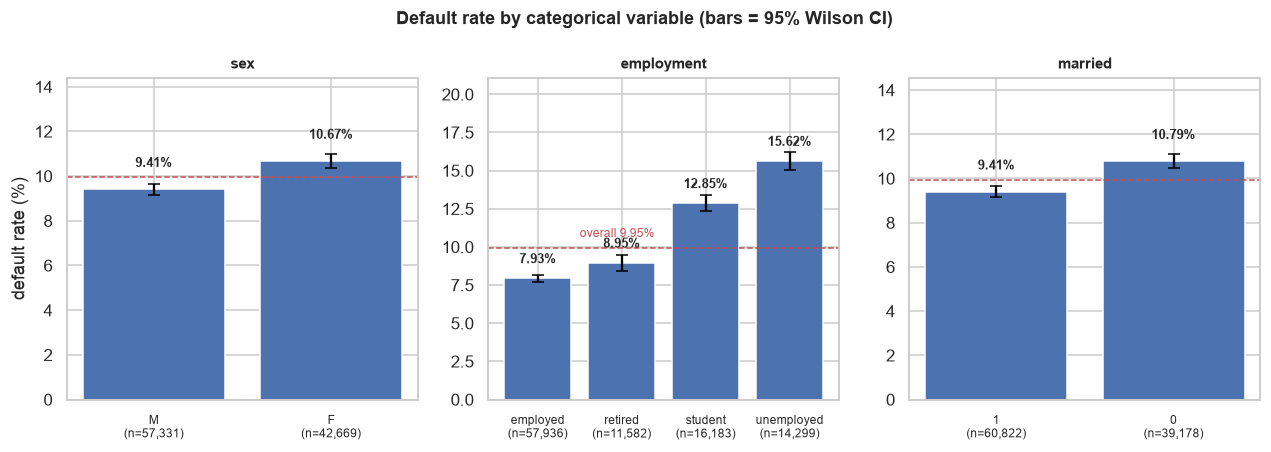

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, v in zip(axes, ["sex", "employment", "married"]):
    g = rate_by(past, v).sort_values("rate")
    xs = np.arange(len(g))
    ax.bar(xs, g["rate"] * 100, color="#4C72B0")
    ax.errorbar(xs, g["rate"] * 100,
                yerr=[(g["rate"] - g["ci_lo"]) * 100, (g["ci_hi"] - g["rate"]) * 100],
                fmt="none", ecolor="black", capsize=4)
    ax.axhline(past["default"].mean() * 100, color="#C44E52", ls="--", lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(g.index, g["n"])], fontsize=8)
    ax.set_title(v, fontsize=10)
    for xi, (r, n) in enumerate(zip(g["rate"] * 100, g["n"])):
        ax.text(xi, r + 1.0, f"{r:.2f}%", ha="center", fontsize=8.5, fontweight="bold")
    ax.set_ylim(0, max(g["rate"]) * 100 * 1.35)
axes[0].set_ylabel("default rate (%)")
axes[1].text(0.5, past["default"].mean() * 100 + 0.7, "overall 9.95%", color="#C44E52", fontsize=8)
fig.suptitle("Default rate by categorical variable (bars = 95% Wilson CI)",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig09_default_by_category.png")
plt.show()

### 5.2 Does `employment` have a natural risk ordering?

This decides one-hot versus ordinal encoding later. Taken at face value the four categories line
up neatly by risk. But the ordering has to be *stable* to justify an ordinal code, so it is worth
checking whether it survives controlling for income — and it does not.

In [32]:
g = rate_by(past, "employment").sort_values("rate")
g["rate_%"] = (g["rate"] * 100).round(2)
print("--- employment, ALL applicants, sorted by default rate ---")
print(g[["n", "defaults", "rate_%", "ci_pm_pp"]].round(2).to_string())
print()
print("gaps between consecutive categories (pp):")
print((g["rate"].diff().dropna() * 100).round(2).to_string())
print()
print("Do neighbouring confidence intervals overlap?")
idx = list(g.index)
for a, b in zip(idx, idx[1:]):
    print(f"  {a:>10} vs {b:<10}: CIs overlap = {g.loc[a, 'ci_hi'] > g.loc[b, 'ci_lo']}")
print()
print("So on all applicants the ranking is clean and the gaps are wide:")
print("  employed 7.93%  <  retired 8.95%  <  student 12.85%  <  unemployed 15.62%")

--- employment, ALL applicants, sorted by default rate ---
                n  defaults  rate_%  ci_pm_pp
employment                                   
employed    57936      4596    7.93      0.22
retired     11582      1037    8.95      0.52
student     16183      2080   12.85      0.52
unemployed  14299      2234   15.62      0.60

gaps between consecutive categories (pp):
employment
retired       1.02
student       3.90
unemployed    2.77

Do neighbouring confidence intervals overlap?
    employed vs retired   : CIs overlap = False
     retired vs student   : CIs overlap = False
     student vs unemployed: CIs overlap = False

So on all applicants the ranking is clean and the gaps are wide:
  employed 7.93%  <  retired 8.95%  <  student 12.85%  <  unemployed 15.62%


In [33]:
print("--- but ALL the income==0 rows are students and unemployed. Re-rank within income > 0 ---")
print()
sub = past[past["income"] > 0]
g2 = rate_by(sub, "employment").sort_values("rate")
g2["rate_%"] = (g2["rate"] * 100).round(2)
g2["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(g2["ci_lo"], g2["ci_hi"])]
print(f"--- employment, income > 0 only (n={len(sub):,}), sorted by default rate ---")
print(g2[["n", "defaults", "rate_%", "CI_%"]].to_string())
print()
r_all = past.groupby("employment")["default"].mean().rank()
r_pos = sub.groupby("employment")["default"].mean().rank()
ranks = pd.DataFrame({"rank among ALL rows": r_all.astype(int),
                      "rank among income>0": r_pos.astype(int)})
print(ranks.to_string())
print(f"\nSpearman correlation between the two rank orders: "
      f"{stats.spearmanr(r_all, r_pos).statistic:+.2f}")
print()
print("--- the full two-way picture ---")
t = rate_by(past.assign(inc0=np.where(past["income"] == 0, "income == 0", "income > 0")),
            ["employment", "inc0"])
t["rate_%"] = (t["rate"] * 100).round(2)
t["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(t["ci_lo"], t["ci_hi"])]
print(t[["n", "defaults", "rate_%", "CI_%"]].to_string())
print()
print("EVIDENCE: the ordering does not just weaken, it REVERSES. Among applicants with positive")
print("income the ranking becomes student 5.90% < unemployed 6.98% < employed 7.93% < retired")
print("8.95% -- exactly the opposite end-to-end from the all-rows ranking, with a rank-order")
print("correlation of -0.60 between the two. Students and the unemployed look risky in aggregate")
print("only because that is where all 17,035 income==0 rows live; those with actual income are the")
print("SAFEST two groups. Employed and retired applicants are unaffected because none of them has")
print("income == 0.")
print()
print("INTERPRETATION (ours): there is no stable risk ordering of the four categories, so an")
print("ordinal code would impose a ranking that holds in one half of the data and inverts in the")
print("other. This is also a strong employment x income==0 interaction, not merely a nuisance.")

--- but ALL the income==0 rows are students and unemployed. Re-rank within income > 0 ---

--- employment, income > 0 only (n=82,965), sorted by default rate ---
                n  defaults  rate_%          CI_%
employment                                       
student      6014       355    5.90  [5.33, 6.53]
unemployed   7433       519    6.98  [6.42, 7.58]
employed    57936      4596    7.93  [7.72, 8.16]
retired     11582      1037    8.95  [8.45, 9.49]

            rank among ALL rows  rank among income>0
employment                                          
employed                      1                    3
retired                       2                    4
student                       3                    1
unemployed                    4                    2

Spearman correlation between the two rank orders: -0.60

--- the full two-way picture ---
                            n  defaults  rate_%            CI_%
employment inc0                                                


saved fig10_employment_ordering.png


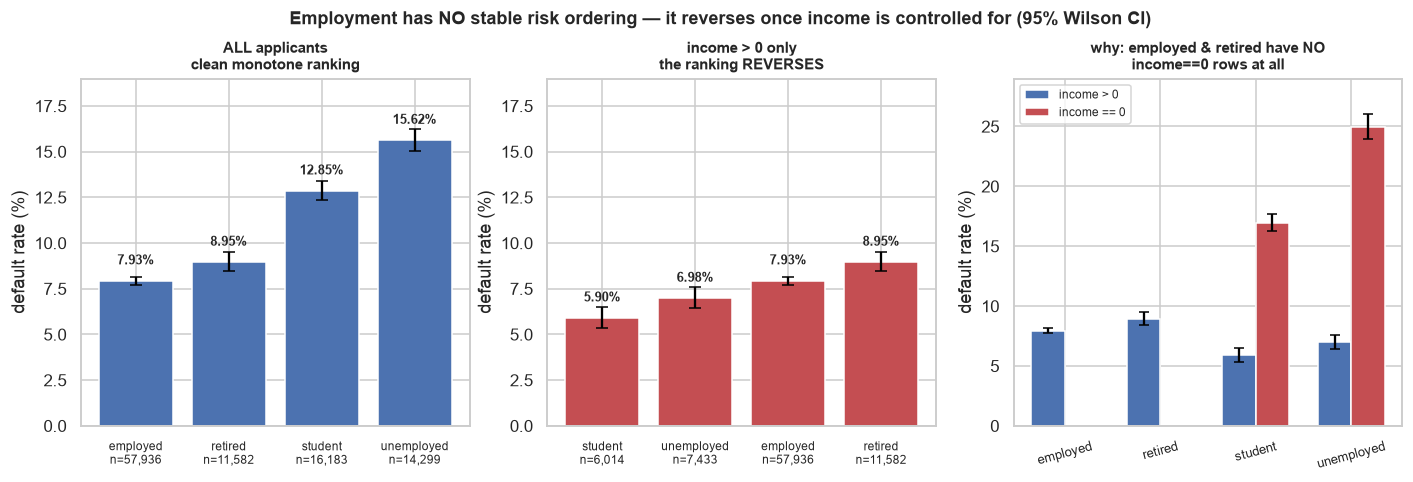

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.1))

ax = axes[0]
g = rate_by(past, "employment").sort_values("rate")
xs = np.arange(len(g))
ax.bar(xs, g["rate"] * 100, color="#4C72B0")
ax.errorbar(xs, g["rate"] * 100, yerr=[(g["rate"] - g["ci_lo"]) * 100, (g["ci_hi"] - g["rate"]) * 100],
            fmt="none", ecolor="black", capsize=4)
ax.set_xticks(xs); ax.set_xticklabels([f"{i}\nn={n:,}" for i, n in zip(g.index, g["n"])], fontsize=8)
ax.set_ylabel("default rate (%)")
ax.set_title("ALL applicants\nclean monotone ranking", fontsize=10)
for xi, r in enumerate(g["rate"] * 100):
    ax.text(xi, r + 0.9, f"{r:.2f}%", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(0, 19)

ax = axes[1]
sub = past[past["income"] > 0]
g2 = rate_by(sub, "employment").sort_values("rate")
xs = np.arange(len(g2))
ax.bar(xs, g2["rate"] * 100, color="#C44E52")
ax.errorbar(xs, g2["rate"] * 100, yerr=[(g2["rate"] - g2["ci_lo"]) * 100, (g2["ci_hi"] - g2["rate"]) * 100],
            fmt="none", ecolor="black", capsize=4)
ax.set_xticks(xs); ax.set_xticklabels([f"{i}\nn={n:,}" for i, n in zip(g2.index, g2["n"])], fontsize=8)
ax.set_ylabel("default rate (%)")
ax.set_title("income > 0 only\nthe ranking REVERSES", fontsize=10)
for xi, r in enumerate(g2["rate"] * 100):
    ax.text(xi, r + 0.9, f"{r:.2f}%", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylim(0, 19)

ax = axes[2]
t = rate_by(past.assign(inc0=past["income"].eq(0)), ["employment", "inc0"])
emps = ["employed", "retired", "student", "unemployed"]
w = 0.35
for j, flag in enumerate([False, True]):
    vals, errs, pos = [], [[], []], []
    for i, e in enumerate(emps):
        if (e, flag) in t.index:
            r = t.loc[(e, flag)]
            vals.append(r["rate"] * 100); pos.append(i + (j - 0.5) * w)
            errs[0].append((r["rate"] - r["ci_lo"]) * 100); errs[1].append((r["ci_hi"] - r["rate"]) * 100)
    ax.bar(pos, vals, w, label="income == 0" if flag else "income > 0",
           color="#C44E52" if flag else "#4C72B0")
    ax.errorbar(pos, vals, yerr=errs, fmt="none", ecolor="black", capsize=3)
ax.set_xticks(range(len(emps))); ax.set_xticklabels(emps, fontsize=8.5, rotation=15)
ax.set_ylabel("default rate (%)")
ax.set_title("why: employed & retired have NO\nincome==0 rows at all", fontsize=10)
ax.legend(fontsize=8)
ax.set_ylim(0, 29)

fig.suptitle("Employment has NO stable risk ordering — it reverses once income is controlled for "
             "(95% Wilson CI)", y=1.03, fontsize=12, fontweight="bold")
savefig(fig, "fig10_employment_ordering.png")
plt.show()

### 5.3 Income vs default, and the `income == 0` question

Your specific question: does the `income == 0` effect survive *within* students and *within* the
unemployed? That separates "having no income is risky" from "being a student or unemployed is
risky". Only those two groups contain income-zero rows, so those are the only two places the
comparison can be made.

In [35]:
print("--- income == 0 vs income > 0, overall ---")
g = rate_by(past.assign(inc0=np.where(past["income"] == 0, "income == 0", "income > 0")), "inc0")
g["rate_%"] = (g["rate"] * 100).round(2)
g["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(g["ci_lo"], g["ci_hi"])]
print(g[["n", "defaults", "rate_%", "CI_%"]].to_string())
print()

print("--- the same comparison WITHIN each employment group ---")
for emp in ["student", "unemployed", "employed", "retired"]:
    sub = past[past["employment"] == emp]
    if (sub["income"] == 0).sum() == 0:
        print(f"{emp:>11}: no income==0 rows at all (n={len(sub):,}) -- comparison not possible")
        continue
    gg = rate_by(sub.assign(inc0=np.where(sub["income"] == 0, "income == 0", "income > 0")), "inc0")
    r0, r1 = gg.loc["income == 0"], gg.loc["income > 0"]
    diff = r0["rate"] - r1["rate"]
    se = np.sqrt(r0["rate"] * (1 - r0["rate"]) / r0["n"] + r1["rate"] * (1 - r1["rate"]) / r1["n"])
    print(f"--- {emp} (n={len(sub):,}) ---")
    print(f"    income == 0: n={int(r0['n']):>6,}  rate {r0['rate'] * 100:6.2f}%  "
          f"CI [{r0['ci_lo'] * 100:.2f}, {r0['ci_hi'] * 100:.2f}]")
    print(f"    income  > 0: n={int(r1['n']):>6,}  rate {r1['rate'] * 100:6.2f}%  "
          f"CI [{r1['ci_lo'] * 100:.2f}, {r1['ci_hi'] * 100:.2f}]")
    print(f"    difference : {diff * 100:+.2f} pp   se {se * 100:.2f} pp   z = {diff / se:+.2f}")
print()
print("Within students and within the unemployed the income==0 rows are compared only with")
print("members of their own employment category, so employment status is held fixed.")

--- income == 0 vs income > 0, overall ---
                 n  defaults  rate_%            CI_%
inc0                                                
income == 0  17035      3440   20.19  [19.60, 20.80]
income > 0   82965      6507    7.84    [7.66, 8.03]

--- the same comparison WITHIN each employment group ---
--- student (n=16,183) ---
    income == 0: n=10,169  rate  16.96%  CI [16.25, 17.71]
    income  > 0: n= 6,014  rate   5.90%  CI [5.33, 6.53]
    difference : +11.06 pp   se 0.48 pp   z = +23.02
--- unemployed (n=14,299) ---
    income == 0: n= 6,866  rate  24.98%  CI [23.97, 26.02]
    income  > 0: n= 7,433  rate   6.98%  CI [6.42, 7.58]
    difference : +18.00 pp   se 0.60 pp   z = +29.98
   employed: no income==0 rows at all (n=57,936) -- comparison not possible
    retired: no income==0 rows at all (n=11,582) -- comparison not possible

Within students and within the unemployed the income==0 rows are compared only with
members of their own employment category, so employment

In [36]:
print("--- is it 'zero' specifically, or just 'low'? income==0 vs the lowest positive incomes ---")
for emp in ["student", "unemployed"]:
    sub = past[past["employment"] == emp]
    pos = sub[sub["income"] > 0]
    # compare income==0 against quartiles of the positive incomes in the same employment group
    qs = pd.qcut(pos["income"], 4, labels=["pos Q1 (lowest)", "pos Q2", "pos Q3", "pos Q4 (highest)"])
    gg = rate_by(pos.assign(q=qs), "q")
    z = rate_by(sub.assign(g=np.where(sub["income"] == 0, "income == 0", "x")), "g").loc["income == 0"]
    print(f"--- {emp} ---")
    print(f"    income == 0      : n={int(z['n']):>6,}  rate {z['rate'] * 100:6.2f}%  "
          f"CI [{z['ci_lo'] * 100:.2f}, {z['ci_hi'] * 100:.2f}]")
    for lab, row in gg.iterrows():
        print(f"    {lab:<17}: n={int(row['n']):>6,}  rate {row['rate'] * 100:6.2f}%  "
              f"CI [{row['ci_lo'] * 100:.2f}, {row['ci_hi'] * 100:.2f}]   "
              f"(median income €{pos.loc[qs == lab, 'income'].median():,.0f})")
    print()

--- is it 'zero' specifically, or just 'low'? income==0 vs the lowest positive incomes ---
--- student ---
    income == 0      : n=10,169  rate  16.96%  CI [16.25, 17.71]
    pos Q1 (lowest)  : n= 1,504  rate  12.83%  CI [11.24, 14.62]   (median income €4,110)
    pos Q2           : n= 1,504  rate   7.18%  CI [5.98, 8.60]   (median income €7,206)
    pos Q3           : n= 1,502  rate   2.46%  CI [1.79, 3.38]   (median income €12,545)
    pos Q4 (highest) : n= 1,504  rate   1.13%  CI [0.71, 1.80]   (median income €26,700)

--- unemployed ---
    income == 0      : n= 6,866  rate  24.98%  CI [23.97, 26.02]
    pos Q1 (lowest)  : n= 1,859  rate  14.79%  CI [13.25, 16.48]   (median income €6,637)
    pos Q2           : n= 1,858  rate   8.56%  CI [7.37, 9.92]   (median income €9,602)
    pos Q3           : n= 1,858  rate   3.55%  CI [2.80, 4.49]   (median income €14,322)
    pos Q4 (highest) : n= 1,858  rate   1.02%  CI [0.66, 1.59]   (median income €26,380)



saved fig11_income_zero_within_employment.png


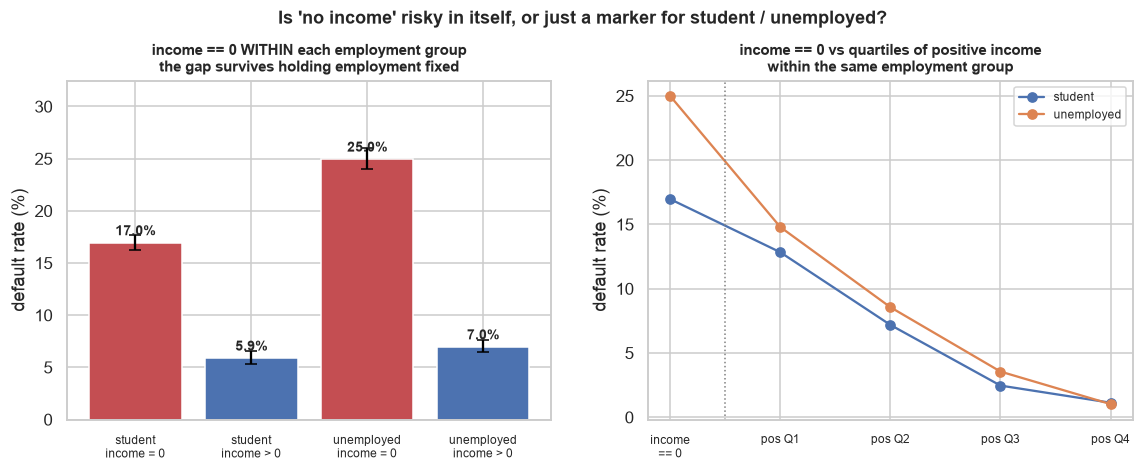

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))

ax = axes[0]
groups, vals, errs, cols = [], [], [[], []], []
for emp in ["student", "unemployed"]:
    sub = past[past["employment"] == emp]
    gg = rate_by(sub.assign(inc0=np.where(sub["income"] == 0, "= 0", "> 0")), "inc0")
    for lab in ["= 0", "> 0"]:
        r = gg.loc[lab]
        groups.append(f"{emp}\nincome {lab}"); vals.append(r["rate"] * 100)
        errs[0].append((r["rate"] - r["ci_lo"]) * 100); errs[1].append((r["ci_hi"] - r["rate"]) * 100)
        cols.append("#C44E52" if lab == "= 0" else "#4C72B0")
xs = np.arange(len(groups))
ax.bar(xs, vals, color=cols)
ax.errorbar(xs, vals, yerr=errs, fmt="none", ecolor="black", capsize=4)
ax.set_xticks(xs); ax.set_xticklabels(groups, fontsize=8)
ax.set_ylabel("default rate (%)")
ax.set_title("income == 0 WITHIN each employment group\nthe gap survives holding employment fixed", fontsize=10)
for xi, v in enumerate(vals):
    ax.text(xi, v + 0.7, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, max(vals) * 1.3)

ax = axes[1]
for emp, colr in [("student", "#4C72B0"), ("unemployed", "#DD8452")]:
    sub = past[past["employment"] == emp]
    pos = sub[sub["income"] > 0]
    qs = pd.qcut(pos["income"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
    gg = rate_by(pos.assign(q=qs), "q")
    zr = sub.loc[sub["income"] == 0, "default"].mean() * 100
    ax.plot([-1] + list(range(4)), [zr] + list(gg["rate"] * 100), "o-", color=colr, label=emp)
ax.axvline(-0.5, color="grey", ls=":", lw=1)
ax.set_xticks([-1, 0, 1, 2, 3])
ax.set_xticklabels(["income\n== 0", "pos Q1", "pos Q2", "pos Q3", "pos Q4"], fontsize=8)
ax.set_ylabel("default rate (%)")
ax.set_title("income == 0 vs quartiles of positive income\nwithin the same employment group", fontsize=10)
ax.legend(fontsize=8)

fig.suptitle("Is 'no income' risky in itself, or just a marker for student / unemployed?",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig11_income_zero_within_employment.png")
plt.show()

### 5.4 Income vs default across bins — raw and log scale

The question for feature engineering is **not** whether a log transform adds information: AUC is
invariant to any strictly monotone transform, so `income` and `log(income)` have *identical*
univariate AUC. The question is whether the log scale makes the relationship closer to **linear
in the log-odds**, which is what a logistic regression assumes.

So the check is: bin income, compute the default rate per bin, convert to log-odds, and see
whether log-odds is closer to a straight line against `income` or against `log(income)`.

**Which rows this fit uses.** The 17,035 rows with `income == 0` are **excluded**; the fit runs on
the 82,965 rows with `income > 0` only. They have to be: `log(0)` is undefined, and the `log1p`
workaround would place all 17,035 of them at exactly `log1p(0) = 0`, far below the next bin, which
would manufacture curvature rather than measure it. The R² comparison therefore says nothing about
how to handle the zeros — that is a separate question, answered in section 5.3.

A `(k+0.5)/(n+1)` continuity correction is applied so the log-odds stays finite in any bin with no
defaults. In these 20 bins it was not actually needed: the sparsest bin still has 10 defaults.

In [38]:
def logit_corrected(k, n):
    """Log-odds of a bin's default rate, with a (k+.5)/(n+1) correction so empty bins stay finite."""
    p = (np.asarray(k, float) + 0.5) / (np.asarray(n, float) + 1)
    return np.log(p / (1 - p))


NB = 20
pos_inc = past[past["income"] > 0].copy()        # log is only defined here
pos_inc["ibin"] = pd.qcut(pos_inc["income"], NB, labels=False)
b = pos_inc.groupby("ibin").agg(n=("default", "size"), k=("default", "sum"),
                                mean_income=("income", "mean"),
                                mean_log_income=("income", lambda s: np.log(s).mean()))
b["rate"] = b["k"] / b["n"]
b["logit"] = logit_corrected(b["k"], b["n"])
lo, hi = wilson_ci(b["k"].to_numpy(), b["n"].to_numpy())
b["ci_lo"], b["ci_hi"] = lo, hi

print(f"--- default rate by {NB} income quantile bins (income > 0 only, n={len(pos_inc):,}) ---")
show = b[["n", "k", "mean_income", "rate", "logit"]].copy()
show["mean_income"] = show["mean_income"].round(0)
show["rate_%"] = (show.pop("rate") * 100).round(2)
show["logit"] = show["logit"].round(3)
print(show.to_string())
print()

for name, x in [("income (raw)", b["mean_income"]), ("log(income)", b["mean_log_income"])]:
    sl, ic, r, p, se = stats.linregress(x, b["logit"])
    print(f"log-odds vs {name:<13}: R^2 = {r**2:.4f}")
print()
print("EVIDENCE: against raw income the log-odds is strongly curved, and a straight line explains")
print("far less of it than against log(income). On the log scale the relationship is close to a")
print("straight line over the bulk of the distribution, flattening only in the top bins where")
print("defaults become very rare.")
print()
print("REMINDER: this is about functional form, not information content --")
print(f"AUC(income) = {roc_auc_score(past['default'], -past['income']):.4f} and "
      f"AUC(log1p(income)) = {roc_auc_score(past['default'], -np.log1p(past['income'])):.4f}, identical by construction.")

--- default rate by 20 income quantile bins (income > 0 only, n=82,965) ---
         n    k  mean_income  logit  rate_%
ibin                                       
0     4151  664       3308.0 -1.658   16.00
1     4150  574       4985.0 -1.829   13.83
2     4145  636       5786.0 -1.707   15.34
3     4152  627       6405.0 -1.726   15.10
4     4147  548       7006.0 -1.881   13.21
5     4150  508       7621.0 -1.969   12.24
6     4144  456       8287.0 -2.089   11.00
7     4148  389       9019.0 -2.267    9.38
8     4151  386       9841.0 -2.277    9.30
9     4147  345      10776.0 -2.398    8.32
10    4146  273      11828.0 -2.651    6.58
11    4148  239      13051.0 -2.793    5.76
12    4151  205      14563.0 -2.955    4.94
13    4145  191      16426.0 -3.028    4.61
14    4149  145      18808.0 -3.315    3.49
15    4149  107      21996.0 -3.627    2.58
16    4147   93      26611.0 -3.770    2.24
17    4148   76      34039.0 -3.975    1.83
18    4148   35      50020.0 -4.752    0.84


saved fig12_default_by_income.png


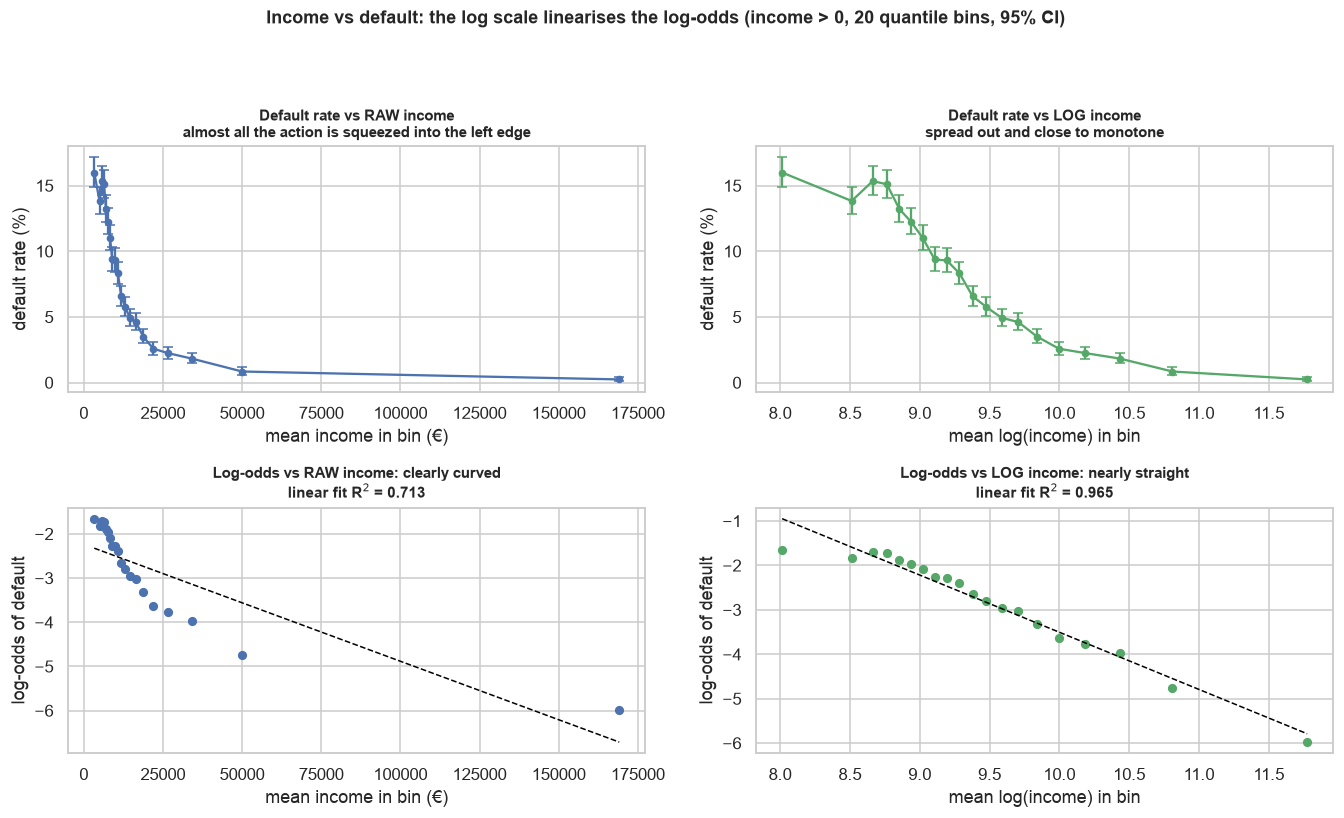

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.5))

ax = axes[0, 0]
ax.errorbar(b["mean_income"], b["rate"] * 100,
            yerr=[(b["rate"] - b["ci_lo"]) * 100, (b["ci_hi"] - b["rate"]) * 100],
            fmt="o-", color="#4C72B0", capsize=3, ms=4)
ax.set_xlabel("mean income in bin (€)"); ax.set_ylabel("default rate (%)")
ax.set_title("Default rate vs RAW income\nalmost all the action is squeezed into the left edge", fontsize=10)

ax = axes[0, 1]
ax.errorbar(b["mean_log_income"], b["rate"] * 100,
            yerr=[(b["rate"] - b["ci_lo"]) * 100, (b["ci_hi"] - b["rate"]) * 100],
            fmt="o-", color="#55A868", capsize=3, ms=4)
ax.set_xlabel("mean log(income) in bin"); ax.set_ylabel("default rate (%)")
ax.set_title("Default rate vs LOG income\nspread out and close to monotone", fontsize=10)

ax = axes[1, 0]
sl, ic, r, p, se = stats.linregress(b["mean_income"], b["logit"])
ax.plot(b["mean_income"], b["logit"], "o", color="#4C72B0", ms=5)
ax.plot(b["mean_income"], ic + sl * b["mean_income"], "--", color="black", lw=1)
ax.set_xlabel("mean income in bin (€)"); ax.set_ylabel("log-odds of default")
ax.set_title(f"Log-odds vs RAW income: clearly curved\nlinear fit R$^2$ = {r**2:.3f}", fontsize=10)

ax = axes[1, 1]
sl2, ic2, r2, p2, se2 = stats.linregress(b["mean_log_income"], b["logit"])
ax.plot(b["mean_log_income"], b["logit"], "o", color="#55A868", ms=5)
ax.plot(b["mean_log_income"], ic2 + sl2 * b["mean_log_income"], "--", color="black", lw=1)
ax.set_xlabel("mean log(income) in bin"); ax.set_ylabel("log-odds of default")
ax.set_title(f"Log-odds vs LOG income: nearly straight\nlinear fit R$^2$ = {r2**2:.3f}", fontsize=10)

fig.suptitle("Income vs default: the log scale linearises the log-odds (income > 0, 20 quantile bins, 95% CI)",
             y=0.99, fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
savefig(fig, "fig12_default_by_income.png")
plt.show()

In [40]:
print("--- the top of the income distribution: where do defaults stop? ---")
print(f"highest income among the {int(past['default'].sum()):,} defaulters: €{past.loc[past['default'] == 1, 'income'].max():,}")
print()
rows = []
for thr in [25_000, 50_000, 75_000, 100_000, 125_000, 150_000, 200_000, INCOME_TOPCODE]:
    sub = past[past["income"] >= thr]
    lo_, hi_ = wilson_ci(int(sub["default"].sum()), len(sub))
    rows.append({"income >= €": f"{thr:,}", "n": len(sub), "defaults": int(sub["default"].sum()),
                 "rate_%": round(sub["default"].mean() * 100, 3),
                 "95% CI_%": f"[{lo_ * 100:.2f}, {hi_ * 100:.2f}]"})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("--- the top-coded applicants specifically ---")
tc = past[past["income"] == INCOME_TOPCODE]
lo_, hi_ = wilson_ci(int(tc["default"].sum()), len(tc))
print(f"n = {len(tc)}, defaults = {int(tc['default'].sum())}, rate = {tc['default'].mean() * 100:.2f}%, "
      f"95% CI = [{lo_ * 100:.2f}%, {hi_ * 100:.2f}%]")
print(f"employment mix: {tc['employment'].value_counts().to_dict()}")
print()
print("EVIDENCE: zero defaults above €150k (1,273 rows) and zero among the 71 top-coded")
print("applicants. But with 71 rows and a zero count, the 95% CI still reaches 5.1%, so 'these")
print("applicants never default' is NOT established -- the data only bound the rate loosely.")
print("INTERPRETATION (ours): the upper income tail is near-separable in this sample, but the")
print("number of observations behind that is small.")

--- the top of the income distribution: where do defaults stop? ---
highest income among the 9,947 defaulters: €123,814

income >= €     n  defaults  rate_%     95% CI_%
     25,000 15705       195   1.242 [1.08, 1.43]
     50,000  6054        19   0.314 [0.20, 0.49]
     75,000  3409         4   0.117 [0.05, 0.30]
    100,000  2284         2   0.088 [0.02, 0.32]
    125,000  1646         0   0.000 [0.00, 0.23]
    150,000  1273         0   0.000 [0.00, 0.30]
    200,000   847         0   0.000 [0.00, 0.45]
  1,000,000    71         0   0.000 [0.00, 5.13]

--- the top-coded applicants specifically ---
n = 71, defaults = 0, rate = 0.00%, 95% CI = [0.00%, 5.13%]
employment mix: {'employed': 66, 'retired': 3, 'unemployed': 1, 'student': 1}

EVIDENCE: zero defaults above €150k (1,273 rows) and zero among the 71 top-coded
applicants. But with 71 rows and a zero count, the 95% CI still reaches 5.1%, so 'these
applicants never default' is NOT established -- the data only bound the rate loosel

### 5.5 Signals vs default: shape of the relationship

Bins are built as in section 0: zeros separately, then deciles of the strictly positive values.
Monotonicity is tested on the positive bins only, since the zero bin is not on the same scale.

In [41]:
for c in SIGNALS:
    b = signal_bins(past[c], q=10)
    g = rate_by(past.assign(b=b), "b")
    g["mean_signal"] = past.assign(b=b).groupby("b", observed=True)[c].mean()
    g["rate_%"] = (g["rate"] * 100).round(2)
    g["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(g["ci_lo"], g["ci_hi"])]
    print(f"--- default rate by bins of {c} ---")
    print(g[["n", "defaults", "mean_signal", "rate_%", "CI_%", "ci_pm_pp"]].round(3).to_string())

    posg = g.drop(index="exactly 0")
    d = posg["rate"].diff().dropna()
    n_up = int((d > 0).sum())
    # which increases are larger than the combined CI half-widths of the two bins involved?
    sig_up = []
    labs = list(posg.index)
    for a, bb in zip(labs, labs[1:]):
        if posg.loc[bb, "rate"] > posg.loc[a, "rate"] and posg.loc[bb, "ci_lo"] > posg.loc[a, "ci_hi"]:
            sig_up.append(f"{a}->{bb}")
    print(f"    positive bins: {n_up} of {len(d)} step-to-step changes go UP (against the trend)")
    print(f"    of those, upward steps with non-overlapping CIs: {sig_up if sig_up else 'none'}")
    print(f"    Spearman rho (positive rows only, signal vs default): "
          f"{stats.spearmanr(past.loc[past[c] > 0, c], past.loc[past[c] > 0, 'default']).statistic:+.4f}")
    print(f"    total drop q1 -> q10: {(posg.loc['q1', 'rate'] - posg.loc['q10', 'rate']) * 100:.2f} pp")
    print()
print("EVIDENCE: all three signals are DECREASING in default risk overall (higher signal = safer),")
print("but the shape is not a straight line: the fall is steep from q1 to about q5 and then")
print("flattens, with small non-monotone wiggles above the median. None of the upward steps has")
print("non-overlapping confidence intervals, so the wiggles are consistent with sampling noise")
print("around a flat upper region rather than a real reversal.")
print()
print("INTERPRETATION (ours): the signals look informative mainly for separating the riskiest")
print("applicants from the rest; among the safer half they discriminate much less, so the")
print("relationship is clearly non-linear in the signal.")

--- default rate by bins of signal1 ---
               n  defaults  mean_signal  rate_%            CI_%  ci_pm_pp
b                                                                        
exactly 0  20837      1977        0.000    9.49    [9.10, 9.89]     0.398
q1          7917      1327        0.062   16.76  [15.95, 17.60]     0.823
q2          7916      1033        0.184   13.05  [12.33, 13.81]     0.742
q3          7916       844        0.286   10.66  [10.00, 11.36]     0.680
q4          7916       848        0.420   10.71  [10.05, 11.41]     0.681
q5          7917       737        0.531    9.31    [8.69, 9.97]     0.640
q6          7916       655        0.592    8.27    [7.69, 8.90]     0.607
q7          7916       605        0.667    7.64    [7.08, 8.25]     0.585
q8          7916       640        0.754    8.08    [7.50, 8.71]     0.601
q9          7916       624        0.843    7.88    [7.31, 8.50]     0.594
q10         7917       657        0.937    8.30    [7.71, 8.93]     0.60

    Spearman rho (positive rows only, signal vs default): -0.0794
    total drop q1 -> q10: 8.46 pp

--- default rate by bins of signal2 ---
               n  defaults  mean_signal  rate_%            CI_%  ci_pm_pp
b                                                                        
exactly 0  20897      2028        0.000    9.70   [9.31, 10.11]     0.401
q1          7911      1273        0.060   16.09  [15.30, 16.92]     0.810
q2          7910      1001        0.180   12.65  [11.94, 13.41]     0.733
q3          7910       828        0.284   10.47   [9.81, 11.16]     0.675
q4          7910       871        0.416   11.01  [10.34, 11.72]     0.690
q5          7911       748        0.529    9.46   [8.83, 10.12]     0.645
q6          7910       682        0.591    8.62    [8.02, 9.26]     0.619
q7          7910       614        0.666    7.76    [7.19, 8.37]     0.590
q8          7910       662        0.753    8.37    [7.78, 9.00]     0.610
q9          7910       626        0.840    7.

---

## 6. How the signals relate to each other and to the public variables

Two questions bear on encoding: are the three signals **redundant** with one another, and do they
**restate public information** that is already in the other columns?

### 6.1 Correlation among the three signals

In [42]:
m_all_pos = (past[SIGNALS] > 0).all(axis=1)

print("--- Pearson correlation among the three signals (all rows, zeros kept as 0) ---")
print(past[SIGNALS].corr().round(4).to_string())
print()
print("--- Spearman correlation among the three signals (all rows) ---")
print(past[SIGNALS].corr(method="spearman").round(4).to_string())
print()
print(f"--- Pearson, rows where ALL THREE signals are positive (n={int(m_all_pos.sum()):,}) ---")
print(past.loc[m_all_pos, SIGNALS].corr().round(4).to_string())
print()
print("--- the two figures side by side, with the row set each one uses ---")
pairs = [("signal1", "signal2"), ("signal1", "signal3"), ("signal2", "signal3")]
tab = []
for lab, df in [("all rows, zeros kept as the number 0", past),
                ("all three signals present (> 0)", past[m_all_pos])]:
    row = {"row set": lab, "n rows": f"{len(df):,}"}
    for a, b in pairs:
        row[f"r({a[-1]},{b[-1]})"] = round(df[[a, b]].corr().iloc[0, 1], 4)
    tab.append(row)
print(pd.DataFrame(tab).to_string(index=False))
print()
print("EVIDENCE: the signals are positively but modestly correlated. WHICH NUMBER TO QUOTE")
print("DEPENDS ON THE ROW SET, and the two differ:")
print("  * 0.174-0.179 over all 100,000 rows, with the zeros left in as the number 0;")
print("  * 0.197-0.200 over the 50,500 rows where all three signals are actually present.")
print("If the zeros are missing values (section 4), the second is the meaningful one: a shared")
print("block of fake 0s inflates nothing but adds noise to the estimate. Both are far from 1 --")
print("at r = 0.20 one signal explains about 4% of another's variance.")

--- Pearson correlation among the three signals (all rows, zeros kept as 0) ---
         signal1  signal2  signal3
signal1   1.0000   0.1739   0.1785
signal2   0.1739   1.0000   0.1788
signal3   0.1785   0.1788   1.0000

--- Spearman correlation among the three signals (all rows) ---
         signal1  signal2  signal3
signal1   1.0000   0.1684   0.1726
signal2   0.1684   1.0000   0.1721
signal3   0.1726   0.1721   1.0000

--- Pearson, rows where ALL THREE signals are positive (n=50,500) ---
         signal1  signal2  signal3
signal1   1.0000   0.1969   0.2003
signal2   0.1969   1.0000   0.1980
signal3   0.2003   0.1980   1.0000

--- the two figures side by side, with the row set each one uses ---
                             row set  n rows  r(1,2)  r(1,3)  r(2,3)
all rows, zeros kept as the number 0 100,000  0.1739  0.1785  0.1788
     all three signals present (> 0)  50,500  0.1969  0.2003  0.1980

EVIDENCE: the signals are positively but modestly correlated. WHICH NUMBER TO QUOTE
DE

### 6.2 Signals versus the public variables

In [43]:
print("--- association between each signal and the public variables ---")
print("For numeric pairs: Pearson and Spearman. For categorical: eta, the square root of the")
print("one-way ANOVA R^2, i.e. the share of signal variation explained by the grouping.")
print()
rows = []
for c in SIGNALS:
    s = past[c]
    grand = s.var(ddof=0)
    etas = {}
    for v in ["sex", "employment"]:
        grp = past.groupby(v)[c]
        between = ((grp.mean() - s.mean()) ** 2 * grp.size()).sum() / len(s)
        etas[v] = np.sqrt(between / grand)
    # same, on the positive values only, to show the zeros are not what drives it
    sp = past.loc[past[c] > 0, c]
    gp = past[past[c] > 0].groupby("employment")[c]
    eta_pos = np.sqrt((((gp.mean() - sp.mean()) ** 2 * gp.size()).sum() / len(sp)) / sp.var(ddof=0))
    rows.append({"signal": c,
                 "pearson vs income": round(stats.pearsonr(s, past["income"]).statistic, 4),
                 "spearman vs income": round(stats.spearmanr(s, past["income"]).statistic, 4),
                 "pearson vs married": round(stats.pearsonr(s, past["married"]).statistic, 4),
                 "eta vs sex": round(etas["sex"], 4),
                 "eta vs employment": round(etas["employment"], 4),
                 "eta vs employment (positives only)": round(eta_pos, 4)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("--- mean signal by employment ---")
allm = past.groupby("employment")[SIGNALS].mean()
posm = pd.DataFrame({c: past[past[c] > 0].groupby("employment")[c].mean() for c in SIGNALS})
print("including zeros as 0:"); print(allm.round(4).to_string())
print("positive values only :"); print(posm.round(4).to_string())
print()
print("EVIDENCE -- and this corrects a natural first guess. The signals are:")
print("  * related to INCOME only weakly, and by an amount that depends on the scale:")
print("      pearson vs raw income   ~ -0.02   (raw income is outlier-dominated, skew 11.9)")
print("      spearman vs income      ~ -0.075  (rank-based, so the right tail no longer dominates)")
print("      pearson vs log1p(income)~ -0.16   (see the decomposition in the next cell)")
print("  * essentially UNRELATED to sex               (eta ~ 0.01)")
print("  * weakly related to marital status           (pearson ~ -0.12)")
print("  * STRONGLY related to employment             (eta ~ 0.40)")
print()
print("The employment relationship is large and is NOT an artefact of the zeros -- restricted to")
print("positive values it gets stronger (eta ~ 0.434-0.436). Mean positive signal runs from 0.210")
print("for the retired to 0.524 for employed and unemployed and 0.687 for students.")
print()
print("INTERPRETATION (ours): a substantial part of each signal restates employment status, which")
print("is already available as a public column. The signals are therefore not fully independent")
print("inputs: employment and the signals carry overlapping information.")

--- association between each signal and the public variables ---
For numeric pairs: Pearson and Spearman. For categorical: eta, the square root of the
one-way ANOVA R^2, i.e. the share of signal variation explained by the grouping.



 signal  pearson vs income  spearman vs income  pearson vs married  eta vs sex  eta vs employment  eta vs employment (positives only)
signal1            -0.0209             -0.0752             -0.1228      0.0127             0.4020                              0.4360
signal2            -0.0199             -0.0780             -0.1170      0.0161             0.3987                              0.4344
signal3            -0.0171             -0.0746             -0.1150      0.0097             0.4003                              0.4338

--- mean signal by employment ---
including zeros as 0:
            signal1  signal2  signal3
employment                           
employed     0.4154   0.4148   0.4130
retired      0.1336   0.1334   0.1331
student      0.6364   0.6317   0.6333
unemployed   0.4101   0.4040   0.4036
positive values only :
            signal1  signal2  signal3
employment                           
employed     0.5257   0.5248   0.5240
retired      0.2097   0.2083   0.2096
stud

#### Why the income figure depends on the scale

The three income correlations above disagree (−0.02 raw, −0.075 Spearman, −0.16 on `log1p`). All
three are real; they weight the data differently. The cell below decomposes the `log1p` figure,
because it is the one a model would actually see if income were log-transformed.

In [44]:
li = np.log1p(past["income"])
zero = past["income"] == 0
pos = ~zero

print("--- where does the -0.16 come from? ---")
for c in SIGNALS:
    r_all = stats.pearsonr(past[c], li).statistic
    r_pos = stats.pearsonr(past.loc[pos, c], np.log(past.loc[pos, "income"])).statistic
    r_flag = stats.pearsonr(past[c], zero.astype(int)).statistic
    print(f"  {c}: all rows vs log1p {r_all:+.4f} | income>0 only, vs log {r_pos:+.4f} "
          f"| vs the income==0 flag {r_flag:+.4f}")
print()
print(f"  log1p(0) = 0.00, and the smallest positive income is EUR {int(past.loc[pos, 'income'].min())} "
      f"-> log1p = {np.log1p(past.loc[pos, 'income'].min()):.2f}")
print(f"  so the {int(zero.sum()):,} zero-income rows sit in a block at 0 with nothing between them")
print(f"  and the rest of the distribution (median log1p among income>0 = {li[pos].median():.2f}).")
print()
print("--- mean signal by income group ---")
g = past.groupby(zero)[SIGNALS].mean().round(4)
g.index = ["income > 0", "income == 0"]
print(g.to_string())
print()
print("--- composition of the income==0 block ---")
comp = pd.DataFrame({
    "% of the income==0 block": (past[zero]["employment"].value_counts(normalize=True) * 100).round(1),
    "% of all rows": (past["employment"].value_counts(normalize=True) * 100).round(1),
    "mean signal3": past.groupby("employment")["signal3"].mean().round(4)})
print(comp.to_string())
w = past["employment"].value_counts(normalize=True)
m = past.groupby("employment")["signal3"].mean()
print(f"\n  if that block had the population employment mix its mean signal3 would be "
      f"{(w * m).sum():.4f}; it is actually {past.loc[zero, 'signal3'].mean():.4f}")
print()
print("--- does zero income itself go with a higher signal, holding employment fixed? ---")
for emp in ["student", "unemployed"]:
    sub = past[past["employment"] == emp]
    print(f"  {emp:>11}: mean signal3 {sub.loc[sub['income'] == 0, 'signal3'].mean():.4f} (income==0) "
          f"vs {sub.loc[sub['income'] > 0, 'signal3'].mean():.4f} (income>0), "
          f"corr with log1p(income) within group {stats.pearsonr(sub['signal3'], np.log1p(sub['income'])).statistic:+.4f}")

--- where does the -0.16 come from? ---
  signal1: all rows vs log1p -0.1585 | income>0 only, vs log +0.0610 | vs the income==0 flag +0.1743


  signal2: all rows vs log1p -0.1567 | income>0 only, vs log +0.0550 | vs the income==0 flag +0.1714
  signal3: all rows vs log1p -0.1562 | income>0 only, vs log +0.0609 | vs the income==0 flag +0.1719

  log1p(0) = 0.00, and the smallest positive income is EUR 6 -> log1p = 1.95
  so the 17,035 zero-income rows sit in a block at 0 with nothing between them
  and the rest of the distribution (median log1p among income>0 = 9.33).

--- mean signal by income group ---
             signal1  signal2  signal3
income > 0    0.3920   0.3905   0.3896
income == 0   0.5429   0.5387   0.5383

--- composition of the income==0 block ---
            % of the income==0 block  % of all rows  mean signal3
employment                                                       
employed                         NaN           57.9        0.4130
retired                          NaN           11.6        0.1331
student                         59.7           16.2        0.6333
unemployed                      40.3    

      student: mean signal3 0.6311 (income==0) vs 0.6370 (income>0), corr with log1p(income) within group +0.0087
   unemployed: mean signal3 0.4007 (income==0) vs 0.4062 (income>0), corr with log1p(income) within group +0.0082


In [45]:
print("EVIDENCE:")
print("  1. Among the 82,965 rows with income > 0 the correlation is +0.055 to +0.061 -- the")
print("     OPPOSITE SIGN to the -0.16 headline. The negative figure comes entirely from the")
print("     zero-income block.")
print("  2. That block has a much higher mean signal (0.538 for signal3) than the income>0 rows")
print("     (0.390), while log1p puts all of it at 0, the bottom of the scale. Low x, high y.")
print("  3. The block is 59.7% students against 16.2% of all rows, and students have the highest")
print("     mean signal of any category (0.633). Given the population employment mix the block's")
print("     mean signal would be 0.415; it is 0.538.")
print("  4. Holding employment fixed, zero income makes essentially NO difference to the signal:")
print("     students 0.6311 (income==0) vs 0.6370 (income>0), unemployed 0.4007 vs 0.4062, with")
print("     within-group correlations of +0.009 and +0.008.")
print()
print("INTERPRETATION (ours): the -0.16 is a COMPOSITION effect, not a relationship between income")
print("and the signals. log1p collapses the 17,035 zero-income applicants into a single block at")
print("the bottom of the income scale, and that block is disproportionately students, who happen")
print("to carry the highest signals. It is not that having no income raises an applicant's signal")
print("-- within students and within the unemployed it does not (point 4). The raw-income Pearson")
print("of -0.02 hides the same block at the other extreme, because raw income is dominated by a")
print("right tail reaching EUR 1,000,000; Spearman's -0.075 sits in between, since ranks tame the")
print("tail but also compress the gap between zero and low positive incomes.")
print()
print("PRACTICAL NOTE: this is another reason log1p(income) should not be used on its own (see")
print("section 5.4) -- on that scale the zero block masquerades as an extreme income value and")
print("drags unrelated associations with it. Pairing the log with an income==0 flag separates the")
print("two, after which the remaining income-signal association is small and positive.")

EVIDENCE:
  1. Among the 82,965 rows with income > 0 the correlation is +0.055 to +0.061 -- the
     OPPOSITE SIGN to the -0.16 headline. The negative figure comes entirely from the
     zero-income block.
  2. That block has a much higher mean signal (0.538 for signal3) than the income>0 rows
     (0.390), while log1p puts all of it at 0, the bottom of the scale. Low x, high y.
  3. The block is 59.7% students against 16.2% of all rows, and students have the highest
     mean signal of any category (0.633). Given the population employment mix the block's
     mean signal would be 0.415; it is 0.538.
  4. Holding employment fixed, zero income makes essentially NO difference to the signal:
     students 0.6311 (income==0) vs 0.6370 (income>0), unemployed 0.4007 vs 0.4062, with
     within-group correlations of +0.009 and +0.008.

INTERPRETATION (ours): the -0.16 is a COMPOSITION effect, not a relationship between income
and the signals. log1p collapses the 17,035 zero-income applicants 

saved fig13_correlations.png


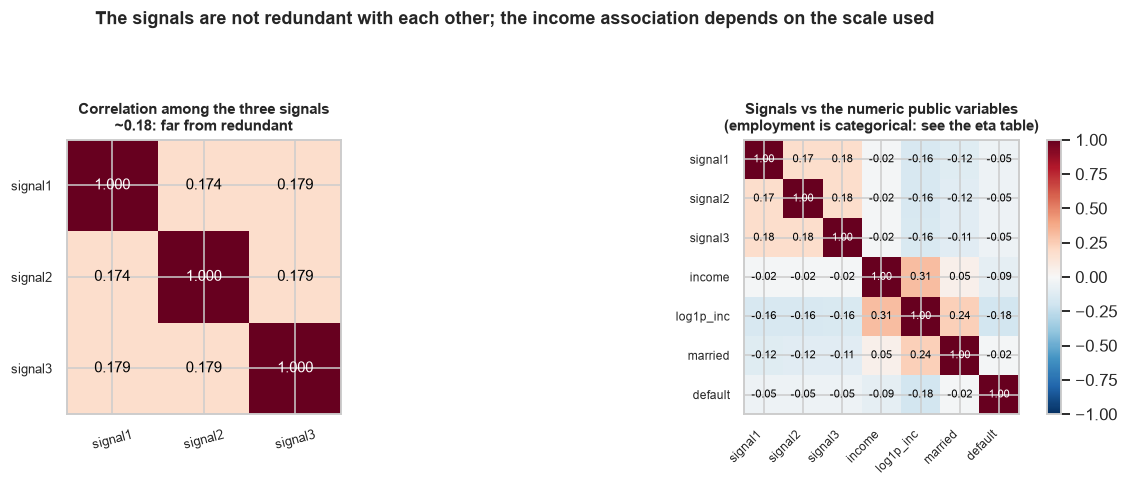

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
corr = past[SIGNALS].corr()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(SIGNALS, fontsize=8.5, rotation=15)
ax.set_yticks(range(3)); ax.set_yticklabels(SIGNALS, fontsize=8.5)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.3f}", ha="center", va="center", fontsize=10,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.set_title("Correlation among the three signals\n~0.18: far from redundant", fontsize=10)

ax = axes[1]
num = past[SIGNALS + ["income", "married", "default"]].copy()
num.insert(4, "log1p_inc", np.log1p(past["income"]))
cm = num.corr()
labs = list(cm.columns)
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=8, rotation=45, ha="right")
ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs, fontsize=8)
for i in range(len(labs)):
    for j in range(len(labs)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(cm.iloc[i, j]) > 0.6 else "black")
ax.set_title("Signals vs the numeric public variables\n(employment is categorical: see the eta table)",
             fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("The signals are not redundant with each other; the income association depends on the scale used",
             y=1.00, fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
savefig(fig, "fig13_correlations.png")
plt.show()

### 6.3 Univariate predictive power (AUC)

Each variable is scored **on its own**, with no model fitted. Conventions:

* AUC is oriented so that higher means more predictive; for variables where higher values mean
  *lower* risk the score used is the negated variable.
* Categorical variables are scored by their in-sample group default rate. With four or fewer
  levels and ~100k rows this is a fair reading of their standalone power, though it does use the
  target to order the levels, so it is very slightly optimistic.
* **AUC is invariant to monotone transforms**, so `income` and `log1p(income)` must come out
  identical. They are both listed to make that concrete.

In [47]:
y = past["default"]
rows = []

def add(name, score, note=""):
    rows.append({"variable": name, "AUC": round(roc_auc_score(y, score), 4), "note": note})

add("signal1 (lender 1)", -past["signal1"], "zeros kept as 0")
add("signal2 (lender 2)", -past["signal2"], "zeros kept as 0")
add("signal3 (OURS)", -past["signal3"], "zeros kept as 0")
add("income", -past["income"], "")
add("log1p(income)", -np.log1p(past["income"]), "identical to income by construction")
add("income == 0 flag", (past["income"] == 0).astype(int), "binary")
for v in ["employment", "sex", "married"]:
    add(v, past[v].map(past.groupby(v)["default"].mean()), "scored by group default rate")
add("signal3 == 0 flag", -(past["signal3"] == 0).astype(int), "binary; direction fitted")

auc_tab = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
print("--- univariate AUC, PastLoans, n=100,000 ---")
print(auc_tab.to_string(index=False))
print()
print("--- the same signals measured only on rows where that signal is present (> 0) ---")
for c in SIGNALS:
    m = past[c] > 0
    print(f"    {c}: AUC = {roc_auc_score(past.loc[m, 'default'], -past.loc[m, c]):.4f}  (n = {int(m.sum()):,})")

--- univariate AUC, PastLoans, n=100,000 ---
          variable    AUC                                note
            income 0.7095                                    
     log1p(income) 0.7095 identical to income by construction
  income == 0 flag 0.5974                              binary
        employment 0.5790        scored by group default rate
    signal3 (OURS) 0.5446                     zeros kept as 0
signal1 (lender 1) 0.5429                     zeros kept as 0
signal2 (lender 2) 0.5425                     zeros kept as 0
           married 0.5184        scored by group default rate
               sex 0.5172        scored by group default rate
 signal3 == 0 flag 0.5033            binary; direction fitted

--- the same signals measured only on rows where that signal is present (> 0) ---
    signal1: AUC = 0.5762  (n = 79,163)
    signal2: AUC = 0.5720  (n = 79,103)
    signal3: AUC = 0.5763  (n = 78,945)


saved fig14_univariate_auc.png


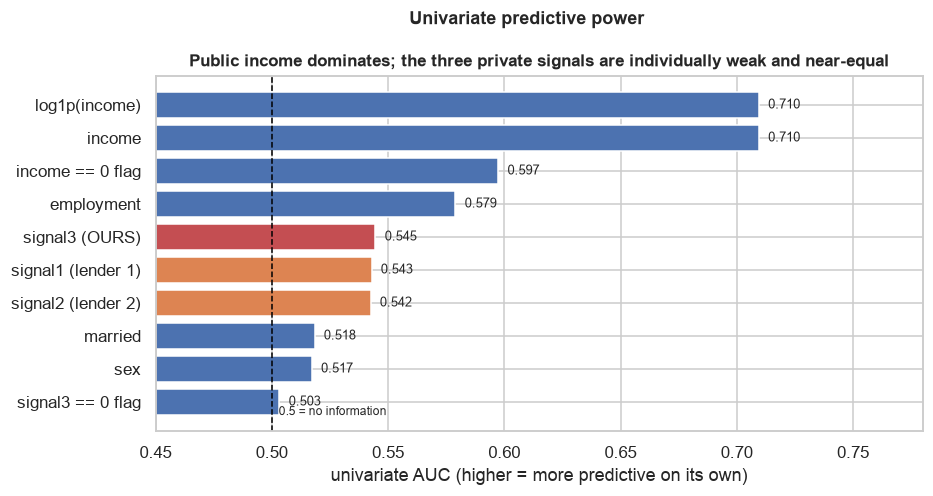

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.2))
t = auc_tab.sort_values("AUC")
cols = ["#C44E52" if "OURS" in v else ("#DD8452" if "lender" in v else "#4C72B0") for v in t["variable"]]
ax.barh(t["variable"], t["AUC"], color=cols)
ax.axvline(0.5, color="black", lw=1, ls="--")
ax.text(0.503, -0.4, "0.5 = no information", fontsize=8)
ax.set_xlim(0.45, 0.78)
ax.set_xlabel("univariate AUC (higher = more predictive on its own)")
for i, (v, a) in enumerate(zip(t["variable"], t["AUC"])):
    ax.text(a + 0.004, i, f"{a:.3f}", va="center", fontsize=8.5)
ax.set_title("Public income dominates; the three private signals are individually weak and near-equal",
             fontsize=11)
fig.suptitle("Univariate predictive power", y=1.02, fontsize=12, fontweight="bold")
savefig(fig, "fig14_univariate_auc.png")
plt.show()

---

## 7. Exploratory look at interactions

Does a variable's relationship with default *change* across groups? These are descriptive looks
only — no models are fitted, and nothing here is a decision.

In [49]:
print("=== 7.1 signal3 vs default, within each employment category ===")
print()
rows = []
for emp in ["employed", "retired", "student", "unemployed"]:
    sub = past[past["employment"] == emp]
    pos = sub[sub["signal3"] > 0]
    qs = pd.qcut(pos["signal3"], 5, labels=["s1", "s2", "s3", "s4", "s5"])
    g = rate_by(pos.assign(q=qs), "q")
    zr = sub.loc[sub["signal3"] == 0, "default"]
    print(f"--- {emp} (n={len(sub):,}; base rate {sub['default'].mean() * 100:.2f}%) ---")
    print(f"    signal3 == 0: n={len(zr):>6,}  rate {zr.mean() * 100:6.2f}%")
    for lab, r in g.iterrows():
        print(f"    {lab} (positive quintile): n={int(r['n']):>6,}  rate {r['rate'] * 100:6.2f}%  "
              f"CI [{r['ci_lo'] * 100:.2f}, {r['ci_hi'] * 100:.2f}]")
    drop = (g.loc["s1", "rate"] - g.loc["s5", "rate"]) * 100
    ratio = g.loc["s1", "rate"] / g.loc["s5", "rate"] if g.loc["s5", "rate"] > 0 else np.nan
    auc_in = roc_auc_score(sub["default"], -sub["signal3"]) if sub["default"].nunique() > 1 else np.nan
    print(f"    q1->q5 drop: {drop:+.2f} pp   risk ratio s1/s5: {ratio:.2f}   "
          f"AUC of signal3 within this group: {auc_in:.4f}")
    print()
    rows.append({"employment": emp, "n": len(sub), "base_rate_%": round(sub["default"].mean() * 100, 2),
                 "s1_%": round(g.loc["s1", "rate"] * 100, 2), "s5_%": round(g.loc["s5", "rate"] * 100, 2),
                 "drop_pp": round(drop, 2), "ratio_s1_s5": round(ratio, 2), "AUC_within": round(auc_in, 4)})
print("--- summary ---")
print(pd.DataFrame(rows).to_string(index=False))
print()
print("EVIDENCE: signal3 separates risk inside every employment category, so its effect is not an")
print("artefact of employment mix. But the SIZE of the gap scales with the group's base rate --")
print("largest in absolute percentage points where defaults are common (student, unemployed),")
print("smallest for the retired, whose base rate is low. The s1/s5 RATIO is much more stable.")
print()
print("INTERPRETATION (ours): dividing each curve by its group's base rate makes the four nearly")
print("coincide, so the signal shifts risk by roughly a constant FACTOR rather than a constant")
print("number of percentage points. On that reading an explicit signal x employment interaction")
print("has little left to capture, though this is suggestive rather than conclusive.")

=== 7.1 signal3 vs default, within each employment category ===

--- employed (n=57,936; base rate 7.93%) ---
    signal3 == 0: n=12,272  rate   8.28%
    s1 (positive quintile): n= 9,133  rate  12.62%  CI [11.96, 13.32]
    s2 (positive quintile): n= 9,133  rate   8.74%  CI [8.18, 9.33]
    s3 (positive quintile): n= 9,132  rate   6.98%  CI [6.47, 7.52]
    s4 (positive quintile): n= 9,133  rate   5.75%  CI [5.29, 6.24]
    s5 (positive quintile): n= 9,133  rate   5.11%  CI [4.68, 5.58]
    q1->q5 drop: +7.51 pp   risk ratio s1/s5: 2.47   AUC of signal3 within this group: 0.5697

--- retired (n=11,582; base rate 8.95%) ---
    signal3 == 0: n= 4,227  rate   9.04%
    s1 (positive quintile): n= 1,471  rate  15.57%  CI [13.80, 17.51]
    s2 (positive quintile): n= 1,471  rate   8.97%  CI [7.62, 10.54]
    s3 (positive quintile): n= 1,471  rate   8.29%  CI [6.99, 9.81]
    s4 (positive quintile): n= 1,471  rate   5.91%  CI [4.82, 7.24]
    s5 (positive quintile): n= 1,471  rate   5.78%  

saved fig15_interaction_signal_employment.png


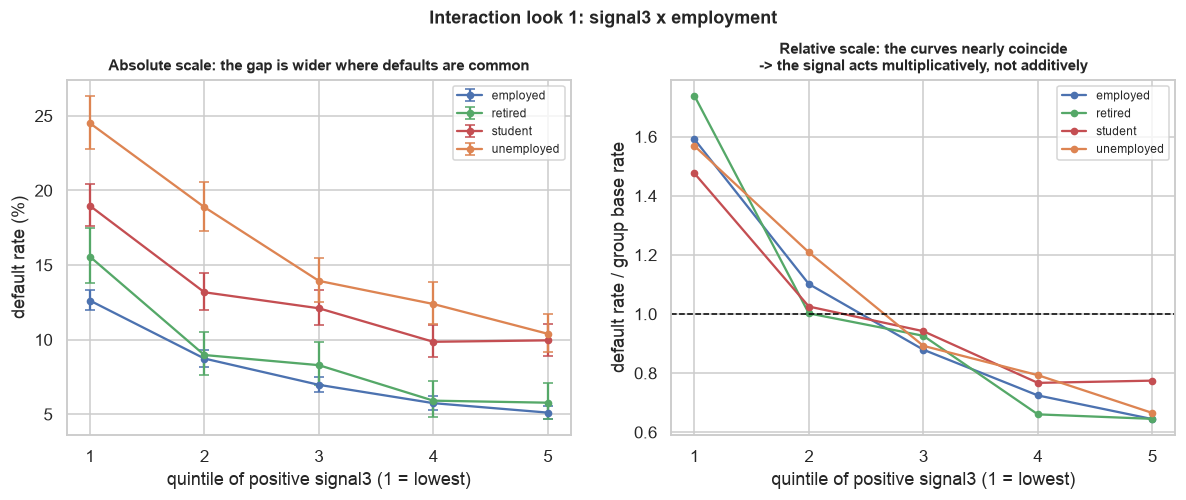

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

palette = {"employed": "#4C72B0", "retired": "#55A868", "student": "#C44E52", "unemployed": "#DD8452"}
ax = axes[0]
for emp, colr in palette.items():
    sub = past[past["employment"] == emp]
    pos = sub[sub["signal3"] > 0]
    qs = pd.qcut(pos["signal3"], 5, labels=False)
    g = rate_by(pos.assign(q=qs), "q")
    ax.errorbar(range(1, 6), g["rate"] * 100,
                yerr=[(g["rate"] - g["ci_lo"]) * 100, (g["ci_hi"] - g["rate"]) * 100],
                fmt="o-", color=colr, capsize=3, ms=4, label=emp)
ax.set_xticks(range(1, 6)); ax.set_xlabel("quintile of positive signal3 (1 = lowest)")
ax.set_ylabel("default rate (%)")
ax.set_title("Absolute scale: the gap is wider where defaults are common", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
for emp, colr in palette.items():
    sub = past[past["employment"] == emp]
    pos = sub[sub["signal3"] > 0]
    qs = pd.qcut(pos["signal3"], 5, labels=False)
    g = rate_by(pos.assign(q=qs), "q")
    ax.plot(range(1, 6), g["rate"] / sub["default"].mean(), "o-", color=colr, ms=4, label=emp)
ax.axhline(1.0, color="black", ls="--", lw=1)
ax.set_xticks(range(1, 6)); ax.set_xlabel("quintile of positive signal3 (1 = lowest)")
ax.set_ylabel("default rate / group base rate")
ax.set_title("Relative scale: the curves nearly coincide\n-> the signal acts multiplicatively, not additively", fontsize=10)
ax.legend(fontsize=8)

fig.suptitle("Interaction look 1: signal3 x employment", y=1.03, fontsize=12, fontweight="bold")
savefig(fig, "fig15_interaction_signal_employment.png")
plt.show()

In [51]:
print("=== 7.2 signal3 vs default, split by income == 0 ===")
print()
for lab, mask in [("income == 0", past["income"] == 0), ("income > 0", past["income"] > 0)]:
    sub = past[mask]
    pos = sub[sub["signal3"] > 0]
    qs = pd.qcut(pos["signal3"], 5, labels=["s1", "s2", "s3", "s4", "s5"])
    g = rate_by(pos.assign(q=qs), "q")
    print(f"--- {lab} (n={len(sub):,}; base rate {sub['default'].mean() * 100:.2f}%) ---")
    for l2, r in g.iterrows():
        print(f"    {l2}: n={int(r['n']):>6,}  rate {r['rate'] * 100:6.2f}%  "
              f"CI [{r['ci_lo'] * 100:.2f}, {r['ci_hi'] * 100:.2f}]")
    print(f"    AUC of signal3 within this group: {roc_auc_score(sub['default'], -sub['signal3']):.4f}")
    print(f"    s1/s5 ratio: {g.loc['s1', 'rate'] / g.loc['s5', 'rate']:.2f}")
    print()

print("=== 7.3 income vs default, within each employment category (income > 0) ===")
print()
for emp in ["employed", "retired", "student", "unemployed"]:
    sub = past[(past["employment"] == emp) & (past["income"] > 0)]
    if len(sub) < 500:
        print(f"{emp}: only n={len(sub)}, skipped")
        continue
    qs = pd.qcut(sub["income"], 5, labels=["i1", "i2", "i3", "i4", "i5"])
    g = rate_by(sub.assign(q=qs), "q")
    meds = sub.groupby(qs, observed=True)["income"].median()
    print(f"--- {emp} (n={len(sub):,}) ---")
    for lab, r in g.iterrows():
        print(f"    {lab}: n={int(r['n']):>6,}  median €{meds[lab]:>8,.0f}  rate {r['rate'] * 100:6.2f}%  "
              f"CI [{r['ci_lo'] * 100:.2f}, {r['ci_hi'] * 100:.2f}]")
    print(f"    AUC of income within this group: {roc_auc_score(sub['default'], -sub['income']):.4f}")
    print()

print("=== 7.4 sex x married ===")
print()
t = rate_by(past, ["sex", "married"])
t["rate_%"] = (t["rate"] * 100).round(2)
t["CI_%"] = [f"[{lo * 100:.2f}, {hi * 100:.2f}]" for lo, hi in zip(t["ci_lo"], t["ci_hi"])]
print(t[["n", "defaults", "rate_%", "CI_%"]].to_string())
f_gap = t.loc[("F", 0), "rate"] - t.loc[("F", 1), "rate"]
m_gap = t.loc[("M", 0), "rate"] - t.loc[("M", 1), "rate"]
print(f"\nmarriage gap (unmarried minus married): F {f_gap * 100:+.2f} pp | M {m_gap * 100:+.2f} pp")
print("EVIDENCE: the marriage effect runs in the same direction and is of similar size for both")
print("sexes, so there is no strong sign of a sex x married interaction.")

=== 7.2 signal3 vs default, split by income == 0 ===

--- income == 0 (n=17,035; base rate 20.19%) ---
    s1: n= 2,928  rate  30.67%  CI [29.03, 32.36]
    s2: n= 2,927  rate  22.21%  CI [20.74, 23.75]
    s3: n= 2,927  rate  19.51%  CI [18.11, 20.98]
    s4: n= 2,927  rate  14.76%  CI [13.52, 16.09]
    s5: n= 2,928  rate  13.11%  CI [11.94, 14.39]
    AUC of signal3 within this group: 0.5854
    s1/s5 ratio: 2.34

--- income > 0 (n=82,965; base rate 7.84%) ---
    s1: n=12,862  rate  12.45%  CI [11.89, 13.03]
    s2: n=12,861  rate   8.48%  CI [8.01, 8.97]
    s3: n=12,862  rate   7.19%  CI [6.76, 7.65]
    s4: n=12,861  rate   5.64%  CI [5.25, 6.05]
    s5: n=12,862  rate   4.94%  CI [4.58, 5.33]
    AUC of signal3 within this group: 0.5678
    s1/s5 ratio: 2.52

=== 7.3 income vs default, within each employment category (income > 0) ===

--- employed (n=57,936) ---
    i1: n=11,591  median €   6,264  rate  16.00%  CI [15.34, 16.67]
    i2: n=11,585  median €   8,760  rate  11.27% 

saved fig16_interactions_other.png


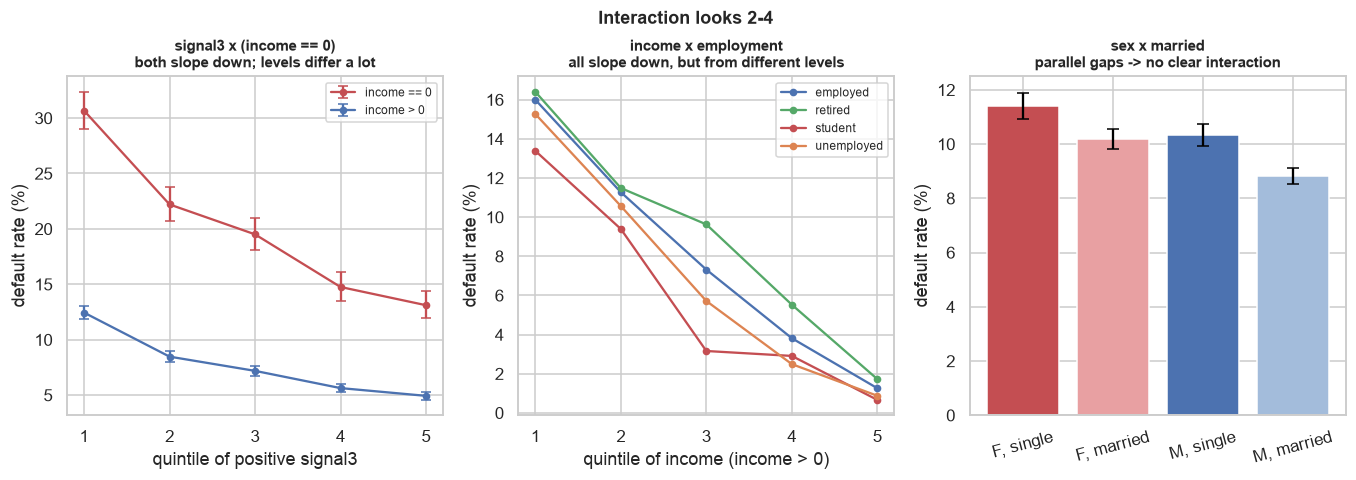

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
for lab, mask, colr in [("income == 0", past["income"] == 0, "#C44E52"),
                        ("income > 0", past["income"] > 0, "#4C72B0")]:
    sub = past[mask]; pos = sub[sub["signal3"] > 0]
    qs = pd.qcut(pos["signal3"], 5, labels=False)
    g = rate_by(pos.assign(q=qs), "q")
    ax.errorbar(range(1, 6), g["rate"] * 100,
                yerr=[(g["rate"] - g["ci_lo"]) * 100, (g["ci_hi"] - g["rate"]) * 100],
                fmt="o-", color=colr, capsize=3, ms=4, label=lab)
ax.set_xticks(range(1, 6)); ax.set_xlabel("quintile of positive signal3")
ax.set_ylabel("default rate (%)"); ax.legend(fontsize=8)
ax.set_title("signal3 x (income == 0)\nboth slope down; levels differ a lot", fontsize=10)

ax = axes[1]
for emp, colr in [("employed", "#4C72B0"), ("retired", "#55A868"),
                  ("student", "#C44E52"), ("unemployed", "#DD8452")]:
    sub = past[(past["employment"] == emp) & (past["income"] > 0)]
    qs = pd.qcut(sub["income"], 5, labels=False)
    g = rate_by(sub.assign(q=qs), "q")
    ax.plot(range(1, 6), g["rate"] * 100, "o-", color=colr, ms=4, label=emp)
ax.set_xticks(range(1, 6)); ax.set_xlabel("quintile of income (income > 0)")
ax.set_ylabel("default rate (%)"); ax.legend(fontsize=8)
ax.set_title("income x employment\nall slope down, but from different levels", fontsize=10)

ax = axes[2]
t = rate_by(past, ["sex", "married"])
labs = ["F, single", "F, married", "M, single", "M, married"]
vals = [t.loc[("F", 0), "rate"], t.loc[("F", 1), "rate"], t.loc[("M", 0), "rate"], t.loc[("M", 1), "rate"]]
err_lo = [t.loc[k, "rate"] - t.loc[k, "ci_lo"] for k in [("F", 0), ("F", 1), ("M", 0), ("M", 1)]]
err_hi = [t.loc[k, "ci_hi"] - t.loc[k, "rate"] for k in [("F", 0), ("F", 1), ("M", 0), ("M", 1)]]
ax.bar(labs, [v * 100 for v in vals], color=["#C44E52", "#E8A0A2", "#4C72B0", "#A3BCDB"])
ax.errorbar(labs, [v * 100 for v in vals],
            yerr=[[e * 100 for e in err_lo], [e * 100 for e in err_hi]],
            fmt="none", ecolor="black", capsize=4)
ax.set_ylabel("default rate (%)")
ax.set_title("sex x married\nparallel gaps -> no clear interaction", fontsize=10)
ax.tick_params(axis="x", rotation=15)

fig.suptitle("Interaction looks 2-4", y=1.03, fontsize=12, fontweight="bold")
savefig(fig, "fig16_interactions_other.png")
plt.show()

---

## 8. Sanity check: are the new applicants the same population?

The brief says the new applicants come from the same population with the same determinants of
default. Worth verifying, because every model is fitted on `PastLoans` and applied to the new file.

**Caveat on the p-values below:** with 100,000 rows in each file these tests have enough power to
flag differences far too small to matter in practice, so a rejection would not by itself be
alarming. As it turns out none of them rejects. The effect sizes (percentage-point and quantile
differences) are the useful numbers; the p-values are reported for completeness.

In [53]:
print("--- categorical variables: two-proportion z-tests ---")
rows = []
for col in ["sex", "employment", "married"]:
    for lvl in sorted(past[col].unique(), key=str):
        p1 = (past[col] == lvl).mean(); p2 = (new[col] == lvl).mean()
        n1, n2 = len(past), len(new)
        pp = ((past[col] == lvl).sum() + (new[col] == lvl).sum()) / (n1 + n2)
        se = np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
        z = (p2 - p1) / se
        rows.append({"variable": col, "level": lvl, "past_%": round(p1 * 100, 2),
                     "new_%": round(p2 * 100, 2), "diff_pp": round((p2 - p1) * 100, 2),
                     "z": round(z, 2), "p": f"{2 * stats.norm.sf(abs(z)):.3f}"})
print(pd.DataFrame(rows).to_string(index=False))
print()

print("--- chi-square test of the full employment distribution ---")
ct = pd.crosstab(pd.concat([pd.Series("past", index=past.index), pd.Series("new", index=new.index)],
                           ignore_index=True),
                 pd.concat([past["employment"], new["employment"]], ignore_index=True))
chi2, pv, dof, _ = stats.chi2_contingency(ct)
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {pv:.3f}")

--- categorical variables: two-proportion z-tests ---


  variable      level  past_%  new_%  diff_pp     z     p
       sex          F   42.67  42.83     0.16  0.74 0.461
       sex          M   57.33  57.17    -0.16 -0.74 0.461
employment   employed   57.94  57.82    -0.11 -0.50 0.615
employment    retired   11.58  11.59     0.01  0.04 0.967
employment    student   16.18  16.05    -0.13 -0.81 0.419
employment unemployed   14.30  14.54     0.24  1.52 0.130
   married          0   39.18  38.90    -0.27 -1.26 0.209
   married          1   60.82  61.10     0.27  1.26 0.209

--- chi-square test of the full employment distribution ---
chi2 = 2.62, dof = 3, p = 0.454


In [54]:
print("--- continuous variables: quantile comparison and KS test ---")
for col in ["income", "signal3"]:
    a, b = past[col], new[col]
    qs = [0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
    qa, qb = np.quantile(a, qs), np.quantile(b, qs)
    print(f"--- {col} ---")
    print(pd.DataFrame({"quantile": qs, "PastLoans": np.round(qa, 4), "NewApplications": np.round(qb, 4),
                        "diff": np.round(qb - qa, 4)}).to_string(index=False))
    ks = stats.ks_2samp(a, b)
    print(f"    mean: {a.mean():.4f} vs {b.mean():.4f}   |   sd: {a.std():.4f} vs {b.std():.4f}")
    print(f"    KS statistic = {ks.statistic:.5f}, p = {ks.pvalue:.3f}")
    print(f"    (a KS statistic of {ks.statistic:.5f} means the two CDFs never differ by more than "
          f"{ks.statistic * 100:.2f} percentage points)")
    print()

print("--- the special features of income, in both files ---")
cmp = pd.DataFrame({
    "PastLoans": [(past["income"] == 0).mean() * 100, (past["income"] == INCOME_TOPCODE).mean() * 100,
                  (past["signal3"] == 0).mean() * 100, past["income"].skew()],
    "NewApplications": [(new["income"] == 0).mean() * 100, (new["income"] == INCOME_TOPCODE).mean() * 100,
                        (new["signal3"] == 0).mean() * 100, new["income"].skew()]},
    index=["share income == 0 (%)", "share income == €1M (%)", "share signal3 == 0 (%)", "income skew"])
cmp["diff"] = cmp["NewApplications"] - cmp["PastLoans"]
print(cmp.round(3).to_string())
print()
print("EVIDENCE: every public variable and signal3 match closely -- category shares within 0.24 pp,")
print("income quantiles within a few tens of euros, signal3 quantiles within 0.003, KS statistics")
print("below 0.005, and no test rejects at the 5% level. The share of income==0 (17.04% vs 17.16%),")
print("the top-code share and the share of signal3==0 (21.06% vs 20.94%) all line up.")
print()
print("INTERPRETATION (ours): consistent with the brief's claim of a common population. Note this")
print("checks the DISTRIBUTION of inputs only. We cannot check that the default MECHANISM is")
print("unchanged, because the new file has no outcomes -- that part has to be taken on trust.")

--- continuous variables: quantile comparison and KS test ---
--- income ---
 quantile  PastLoans  NewApplications     diff
     0.01       0.00             0.00     0.00
     0.10       0.00             0.00     0.00
     0.25    5385.00          5363.00   -22.00
     0.50    9370.00          9349.00   -21.00
     0.75   17474.25         17442.00   -32.25
     0.90   34573.20         34576.20     3.00
     0.99  179540.55        177913.55 -1627.00
    mean: 18646.2539 vs 18724.4533   |   sd: 48178.1990 vs 49511.9439
    KS statistic = 0.00265, p = 0.873
    (a KS statistic of 0.00265 means the two CDFs never differ by more than 0.26 percentage points)

--- signal3 ---
 quantile  PastLoans  NewApplications    diff
     0.01     0.0000           0.0000  0.0000
     0.10     0.0000           0.0000  0.0000
     0.25     0.0605           0.0626  0.0021
     0.50     0.4409           0.4464  0.0055
     0.75     0.6924           0.6943  0.0018
     0.90     0.8592           0.8599  0.0007


saved fig17_past_vs_new.png


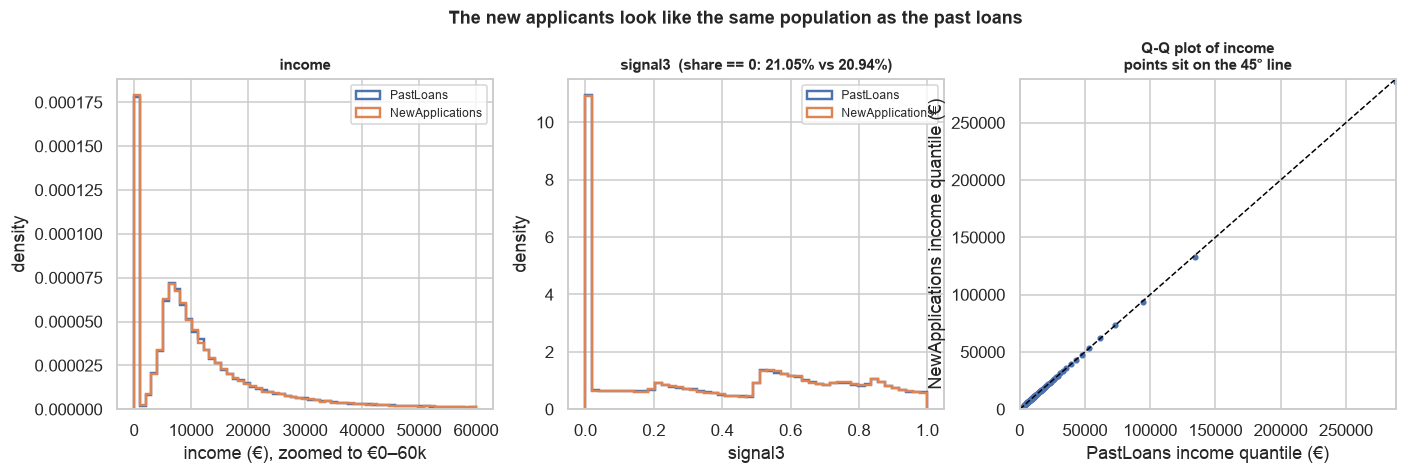

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))

ax = axes[0]
bins = np.linspace(0, 60000, 60)
ax.hist(past["income"], bins=bins, histtype="step", density=True, lw=1.6, color="#4C72B0", label="PastLoans")
ax.hist(new["income"], bins=bins, histtype="step", density=True, lw=1.6, color="#DD8452", label="NewApplications")
ax.set_xlabel("income (€), zoomed to €0–60k"); ax.set_ylabel("density")
ax.set_title("income", fontsize=10); ax.legend(fontsize=8)

ax = axes[1]
bins = np.linspace(0, 1, 50)
ax.hist(past["signal3"], bins=bins, histtype="step", density=True, lw=1.6, color="#4C72B0", label="PastLoans")
ax.hist(new["signal3"], bins=bins, histtype="step", density=True, lw=1.6, color="#DD8452", label="NewApplications")
ax.set_xlabel("signal3"); ax.set_ylabel("density")
ax.set_title(f"signal3  (share == 0: {(past['signal3'] == 0).mean() * 100:.2f}% vs "
             f"{(new['signal3'] == 0).mean() * 100:.2f}%)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
qs = np.linspace(0.005, 0.995, 100)
ax.plot(np.quantile(past["income"], qs), np.quantile(new["income"], qs), "o", ms=3, color="#4C72B0")
lim = [0, np.quantile(past["income"], 0.995)]
ax.plot(lim, lim, "--", color="black", lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("PastLoans income quantile (€)"); ax.set_ylabel("NewApplications income quantile (€)")
ax.set_title("Q-Q plot of income\npoints sit on the 45° line", fontsize=10)

fig.suptitle("The new applicants look like the same population as the past loans",
             y=1.04, fontsize=12, fontweight="bold")
savefig(fig, "fig17_past_vs_new.png")
plt.show()

---

## 9. Data preparation and the train/validation split

This section applies the transformations the team decided on and makes the split. The functions
live in [`src/data_prep.py`](../src/data_prep.py); nothing is defined here, so the notebook and
the modelling parts of the project prepare data with exactly the same code.

All transformations are **stateless** — no mean, median or category list is learned from the data
— so `PastLoans` and the new applications go through the same functions and come out with columns
that mean the same thing. The four `employment` categories are hardcoded in the module for that
reason.

Three versions of the data are produced, because the models want different things:

| function | adds |
|---|---|
| `general_prep_data` | the encodings every model uses |
| `logreg_prep_data` | `income_log1p` and `unemployed_x_income_zero` |
| `boosting_prep_data` | nothing yet — a tree needs neither |

Outputs go to `data/processed/`. The raw files are read-only and are only ever read; the MD5
recorded below is re-checked at the end of the section to show they were not touched.

In [56]:
import hashlib

from src.config import DATA_PROCESSED
from src.data_prep import (
    general_prep_data,
    logreg_prep_data,
    boosting_prep_data,
    split_data,
)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


def file_md5(path):
    """MD5 of a file, used to show the read-only raw inputs come out unmodified."""
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


RAW_MD5_BEFORE = {path: file_md5(path) for path in (PAST_LOANS, NEW_APPS_R1)}

print(f"processed data -> {DATA_PROCESSED.relative_to(DATA_PROCESSED.parents[1])}")
print()
print("--- MD5 of the raw inputs, recorded before any work ---")
for path, digest in RAW_MD5_BEFORE.items():
    print(f"  {path.name:<36} {digest}")

processed data -> data/processed

--- MD5 of the raw inputs, recorded before any work ---
  PastLoans.csv                        8b4e96493b4f64215adae6d07f0232d0
  NewApplications_Lender3_Round1.csv   855f568d2101b10426135c5267cea909


### 9.1 Row identifier and the three prepared versions

`PastLoans` has no `id`, so we add `row_id` numbered `0…99,999` **in the original CSV row order,
before any preparation or splitting**. It is what lets us check further down that the three
versions split identically, and it keeps every prepared row traceable to its raw row. The file is
re-read here rather than reusing `past` from section 1, so the numbering cannot depend on anything
done earlier in the notebook.

In [57]:
past_raw = pd.read_csv(PAST_LOANS)
past_raw.insert(0, "row_id", np.arange(len(past_raw)))

preprocessed_data = general_prep_data(past_raw)
preprocessed_logreg = logreg_prep_data(past_raw)
preprocessed_boosting = boosting_prep_data(past_raw)

for name, frame in [("general", preprocessed_data),
                    ("logreg", preprocessed_logreg),
                    ("boosting", preprocessed_boosting)]:
    print(f"--- {name}: {frame.shape[0]:,} rows x {frame.shape[1]} cols ---")
    print(f"    {list(frame.columns)}")
    print()

--- general: 100,000 rows x 16 cols ---
    ['row_id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal1', 'signal1_missing', 'signal2', 'signal2_missing', 'signal3', 'signal3_missing', 'default']

--- logreg: 100,000 rows x 18 cols ---
    ['row_id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal1', 'signal1_missing', 'signal2', 'signal2_missing', 'signal3', 'signal3_missing', 'income_log1p', 'unemployed_x_income_zero', 'default']

--- boosting: 100,000 rows x 16 cols ---
    ['row_id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal1', 'signal1_missing', 'signal2', 'signal2_missing', 'signal3', 'signal3_missing', 'default']



### 9.2 The split

80/20, stratified on `default`, `random_state = SEED` (42). `split_data` is called separately on
each of the three versions. It receives the same rows in the same order with the same seed every
time, so all three should select the same rows — 9.5 checks that rather than assuming it.

In [58]:
train_general, validation_general = split_data(preprocessed_data)
train_logreg, validation_logreg = split_data(preprocessed_logreg)
train_boosting, validation_boosting = split_data(preprocessed_boosting)

for name, train, validation in [("general", train_general, validation_general),
                                ("logreg", train_logreg, validation_logreg),
                                ("boosting", train_boosting, validation_boosting)]:
    print(f"{name:<9} train {train.shape[0]:>6,} x {train.shape[1]:<3}"
          f"   validation {validation.shape[0]:>6,} x {validation.shape[1]}")

general   train 80,000 x 16    validation 20,000 x 16
logreg    train 80,000 x 18    validation 20,000 x 18
boosting  train 80,000 x 16    validation 20,000 x 16


### 9.3 The new applications

Same three functions, no split: the applications have no outcome and are predicted on as a whole.
They carry `id` instead of `row_id`, and `signal3` alone, so they come out with the general
columns minus `default`, `signal1`, `signal2` and the two signal flags.

In [59]:
apps_raw = pd.read_csv(NEW_APPS_R1)

applications_general = general_prep_data(apps_raw)
applications_logreg = logreg_prep_data(apps_raw)
applications_boosting = boosting_prep_data(apps_raw)

for name, frame in [("general", applications_general),
                    ("logreg", applications_logreg),
                    ("boosting", applications_boosting)]:
    print(f"--- {name}: {frame.shape[0]:,} rows x {frame.shape[1]} cols ---")
    print(f"    {list(frame.columns)}")
    print()

--- general: 100,000 rows x 11 cols ---
    ['id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal3', 'signal3_missing']

--- logreg: 100,000 rows x 13 cols ---
    ['id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal3', 'signal3_missing', 'income_log1p', 'unemployed_x_income_zero']

--- boosting: 100,000 rows x 11 cols ---
    ['id', 'sex_F', 'married', 'employment_employed', 'employment_retired', 'employment_student', 'employment_unemployed', 'income', 'income_zero', 'signal3', 'signal3_missing']



### 9.4 Sanity checks

Columns, missing values, row counts and default rates. The expected column lists are written out
literally so the check is independent of the module's own constants.

In [60]:
# Expected columns, spelled out rather than derived from src/data_prep.py.
EXPECTED_GENERAL = ["row_id", "sex_F", "married",
                    "employment_employed", "employment_retired",
                    "employment_student", "employment_unemployed",
                    "income", "income_zero",
                    "signal1", "signal1_missing",
                    "signal2", "signal2_missing",
                    "signal3", "signal3_missing",
                    "default"]
EXPECTED_LOGREG = [c for c in EXPECTED_GENERAL if c != "default"] + \
                  ["income_log1p", "unemployed_x_income_zero", "default"]
EXPECTED_BOOSTING = EXPECTED_GENERAL

# The applications: same columns, with the identifier renamed and the unavailable ones dropped.
APPS_DROP = ["default", "signal1", "signal1_missing", "signal2", "signal2_missing"]


def apps_expected(cols):
    """The application columns implied by a PastLoans column list."""
    return ["id" if c == "row_id" else c for c in cols if c not in APPS_DROP]


checks = [
    ("train_general", train_general, EXPECTED_GENERAL),
    ("validation_general", validation_general, EXPECTED_GENERAL),
    ("applications_general", applications_general, apps_expected(EXPECTED_GENERAL)),
    ("train_logreg", train_logreg, EXPECTED_LOGREG),
    ("validation_logreg", validation_logreg, EXPECTED_LOGREG),
    ("applications_logreg", applications_logreg, apps_expected(EXPECTED_LOGREG)),
    ("train_boosting", train_boosting, EXPECTED_BOOSTING),
    ("validation_boosting", validation_boosting, EXPECTED_BOOSTING),
    ("applications_boosting", applications_boosting, apps_expected(EXPECTED_BOOSTING)),
]

print("--- columns and missing values ---")
rows = []
for name, frame, expected in checks:
    rows.append({"file": name,
                 "rows": frame.shape[0],
                 "cols": frame.shape[1],
                 "columns as expected": list(frame.columns) == expected,
                 "missing values": int(frame.isna().sum().sum())})
checks_tab = pd.DataFrame(rows)
print(checks_tab.to_string(index=False))
print()

assert all(list(f.columns) == e for _, f, e in checks), "unexpected columns"
assert all(f.isna().sum().sum() == 0 for _, f, _ in checks), "missing values found"
print("OK: every file has exactly the expected columns, and no missing values.")

--- columns and missing values ---
                 file   rows  cols  columns as expected  missing values
        train_general  80000    16                 True               0
   validation_general  20000    16                 True               0
 applications_general 100000    11                 True               0
         train_logreg  80000    18                 True               0
    validation_logreg  20000    18                 True               0
  applications_logreg 100000    13                 True               0
       train_boosting  80000    16                 True               0
  validation_boosting  20000    16                 True               0
applications_boosting 100000    11                 True               0

OK: every file has exactly the expected columns, and no missing values.


In [61]:
print("--- row counts ---")
print(f"PastLoans rows read          : {len(past_raw):,}")
for name, train, validation in [("general", train_general, validation_general),
                                ("logreg", train_logreg, validation_logreg),
                                ("boosting", train_boosting, validation_boosting)]:
    n_tr, n_va = len(train), len(validation)
    print(f"  {name:<9} {n_tr:,} train + {n_va:,} validation = {n_tr + n_va:,}"
          f"   ({n_tr / len(past_raw):.0%} / {n_va / len(past_raw):.0%})")
    assert n_tr + n_va == len(past_raw)
    assert set(train["row_id"]).isdisjoint(validation["row_id"])
print()
print(f"applications rows read       : {len(apps_raw):,}")
for name, frame in [("general", applications_general),
                    ("logreg", applications_logreg),
                    ("boosting", applications_boosting)]:
    print(f"  {name:<9} {len(frame):,}")
    assert len(frame) == len(apps_raw)
print()
print("OK: train and validation partition the 100,000 past loans with no overlap, "
      "and all 100,000 applications come through.")

--- row counts ---
PastLoans rows read          : 100,000
  general   80,000 train + 20,000 validation = 100,000   (80% / 20%)
  logreg    80,000 train + 20,000 validation = 100,000   (80% / 20%)
  boosting  80,000 train + 20,000 validation = 100,000   (80% / 20%)

applications rows read       : 100,000
  general   100,000
  logreg    100,000
  boosting  100,000

OK: train and validation partition the 100,000 past loans with no overlap, and all 100,000 applications come through.


In [62]:
print("--- default rate: train vs validation ---")
rows = []
for name, train, validation in [("general", train_general, validation_general),
                                ("logreg", train_logreg, validation_logreg),
                                ("boosting", train_boosting, validation_boosting)]:
    rows.append({"version": name,
                 "full %": round(preprocessed_data["default"].mean() * 100, 3),
                 "train %": round(train["default"].mean() * 100, 3),
                 "validation %": round(validation["default"].mean() * 100, 3),
                 "train defaults": int(train["default"].sum()),
                 "validation defaults": int(validation["default"].sum())})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("OK: stratification holds the rate to within 0.01 pp of the full sample.")

--- default rate: train vs validation ---
 version  full %  train %  validation %  train defaults  validation defaults
 general   9.947    9.948         9.945            7958                 1989
  logreg   9.947    9.948         9.945            7958                 1989
boosting   9.947    9.948         9.945            7958                 1989

OK: stratification holds the rate to within 0.01 pp of the full sample.


### 9.5 The three versions split identically

They must, or a model's validation rows would be another model's training rows and the comparison
between them would be meaningless. Checked on `row_id` as sets.

In [63]:
train_ids = {"general": set(train_general["row_id"]),
             "logreg": set(train_logreg["row_id"]),
             "boosting": set(train_boosting["row_id"])}
validation_ids = {"general": set(validation_general["row_id"]),
                  "logreg": set(validation_logreg["row_id"]),
                  "boosting": set(validation_boosting["row_id"])}

print("--- row_id sets, compared against the general version ---")
for name in ("logreg", "boosting"):
    same_train = train_ids[name] == train_ids["general"]
    same_validation = validation_ids[name] == validation_ids["general"]
    print(f"  {name:<9} train identical: {same_train}   validation identical: {same_validation}")
    assert same_train and same_validation, f"{name} splits differently"
print()
print(f"OK: all three versions put the same {len(train_ids['general']):,} row_ids in train "
      f"and the same {len(validation_ids['general']):,} in validation.")

--- row_id sets, compared against the general version ---
  logreg    train identical: True   validation identical: True
  boosting  train identical: True   validation identical: True

OK: all three versions put the same 80,000 row_ids in train and the same 20,000 in validation.


### 9.6 Save, and re-check that the raw files are untouched

In [64]:
# Filenames are built from DATA_PROCESSED (src/config.py), one per version and per role.
to_save = {
    "train_general.csv": train_general,
    "validation_general.csv": validation_general,
    "applications_general.csv": applications_general,
    "train_logreg.csv": train_logreg,
    "validation_logreg.csv": validation_logreg,
    "applications_logreg.csv": applications_logreg,
    "train_boosting.csv": train_boosting,
    "validation_boosting.csv": validation_boosting,
    "applications_boosting.csv": applications_boosting,
}

print(f"--- writing to {DATA_PROCESSED.relative_to(DATA_PROCESSED.parents[1])} ---")
for filename, frame in to_save.items():
    path = DATA_PROCESSED / filename
    frame.to_csv(path, index=False)
    print(f"  {filename:<28} {frame.shape[0]:>6,} rows x {frame.shape[1]:<3} "
          f"{path.stat().st_size / 1e6:>5.1f} MB")
print()

print("--- raw inputs unchanged ---")
for path, before in RAW_MD5_BEFORE.items():
    after = file_md5(path)
    print(f"  {path.name:<36} {'unchanged' if after == before else 'CHANGED'}  {after}")
    assert after == before, f"{path.name} was modified"
print()
print("OK: both raw files have the same MD5 as before the section ran.")

--- writing to data/processed ---


  train_general.csv            80,000 rows x 16    4.9 MB


  validation_general.csv       20,000 rows x 16    1.2 MB
  applications_general.csv     100,000 rows x 11    3.6 MB


  train_logreg.csv             80,000 rows x 18    6.3 MB
  validation_logreg.csv        20,000 rows x 18    1.6 MB


  applications_logreg.csv      100,000 rows x 13    5.4 MB
  train_boosting.csv           80,000 rows x 16    4.9 MB


  validation_boosting.csv      20,000 rows x 16    1.2 MB
  applications_boosting.csv    100,000 rows x 11    3.6 MB

--- raw inputs unchanged ---
  PastLoans.csv                        unchanged  8b4e96493b4f64215adae6d07f0232d0
  NewApplications_Lender3_Round1.csv   unchanged  855f568d2101b10426135c5267cea909

OK: both raw files have the same MD5 as before the section ran.
